# ECOM6003 — Combined Notebook: Calibration + Out-of-Sample Quarterly Walk-Forward

One pipeline, structured around the methodology's dot points. Every section states, in its own markdown cell, *why* that step exists and which dot point it implements.

1. **Data Prep -> Screening -> Estimation of Expected Returns -> Estimation of Portfolio Risk -> Construction of Portfolio** — one shared function library used by everything below it.
2. **Experiment Configuration** — the shared boundary dates (`REBALANCE_START`, `COMPARISON_START`, `COMPARISON_END`) that everything else is defined relative to, so they can't drift out of sync with each other.
3. **Validation of Approach — Part A**, all sharing one held-out comparison period (`COMPARISON_START` to `COMPARISON_END` = `REBALANCE_START`), deciding *what the strategy is* before Part B tests whether it works:
   - **Model Comparison** (Carhart vs CAPM vs FF3F) and **Lambda Sensitivity**.
   - **Window/Rebalancing-Frequency Comparison** — a genuine rolling walk-forward: re-screens from scratch at every candidate rebalance date, then hands the winning policy (`ADOPTED_WINDOW_YEARS`, `ADOPTED_REBALANCE_DAYS`) to Part B.
4. **Validation of Approach — Part B** — applies that fixed, adopted policy over the separate, later, non-overlapping reporting period (`REBALANCE_START` onward) — the strategy's actual validated performance.
5. **Quantifying and Validating Downside** — historical-simulation VaR, per quarter, in Part B.

**Two genuinely separate periods, not three:**
1. Calibration + Comparison: `[COMPARISON_START, REBALANCE_START)` — Model Comparison, Lambda Sensitivity, and Window/Frequency Comparison all share this one held-out stretch.
2. Part B reporting: `[REBALANCE_START, today]`.

**Why not three (one earlier attempt at this):** giving each calibration decision (model/lambda vs window/frequency) its own fully separate historical period sounds more rigorous, but with COVID sitting almost exactly in the middle of the available data (2017-2026), pushing far enough back for a third period forced the stock-screening step onto a window spanning the COVID crash, recovery, meme-stock mania, and the 2022 rate-hike bear market — four regime changes back to back — which broke the Chow beta-stability test for nearly every stock and left too few to build a portfolio at all. Sharing one comparison period between the two calibration decisions is a smaller, more honest trade-off: both are informed by the same held-out stretch (a real but minor concern), while what actually matters most — neither one overlapping Part B's reported results — remains fully avoided.

**Fixed along the way:**
- **Screening-overlap leak:** Part A's stock screening used to run through *today* while model training stopped at a fixed test date. Screening now shares training's cutoff.
- **Policy-selection-bias leak:** calibration's test window used to have no upper bound, running into Part B's reporting period. Now bounded at `REBALANCE_START`.
- **Silent crash on infeasible screens:** an empty/tiny screened universe used to reach `yf.download([])` and crash with an opaque pandas/yfinance error. Now raises a clear, explained error instead.

**Still open, flagged rather than silently left:**
- Stage 1 screening's `sharpe > 0` filter (§ *Screening*) is a judgement call beyond the proposal's literal wording.
- Model Comparison/Lambda Sensitivity and Window/Frequency Comparison sharing one period (above) is a real, minor trade-off, not a fully independent test of each decision.
- A **nested walk-forward** (re-running the whole comparison fresh inside every period of Part B, letting the adopted policy evolve over time) would be the next level of rigour beyond this — a substantially larger feature than what's built here.

In [309]:
import sys
!{sys.executable} -m pip install yfinance pandas numpy statsmodels scikit-learn matplotlib lxml ruptures cvxpy -q

In [310]:
import pandas as pd
import numpy as np
import requests
import zipfile
import os
from io import StringIO
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge
import yfinance as yf
import cvxpy as cp

pd.set_option("display.width", 140)

## Data Prep — universe & sector map
(§ *Data Window and Source*, § *Restrictions*: sector cap needs a sector map)

**Why Wikipedia's constituent list:** it's the simplest available source for the current S&P 500 membership and each ticker's GICS sector — needed both for the sector-cap constraint later and as the starting universe for screening. **Limitation carried over from the original proposal:** this is the *current* membership list, not a point-in-time historical one, so it doesn't capture stocks that were removed from the index earlier in the estimation window (survivorship bias) — stated explicitly rather than left implicit.

In [311]:
headers = {"User-Agent": "Mozilla/5.0"}
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
response = requests.get(url, headers=headers)

sp500 = pd.read_html(StringIO(response.text))[0]
tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()
sector_map = sp500.set_index(sp500["Symbol"].str.replace(".", "-", regex=False))["GICS Sector"].to_dict()
print(f"{len(tickers)} tickers, {len(set(sector_map.values()))} GICS sectors")

503 tickers, 11 GICS sectors


### Data Prep — daily adjusted close prices, cleaned for completeness
(§ *Data Prep*: daily adjusted closing prices; drop incomplete trading histories; convert to log returns)

**One unified download**, starting further back (2019-06-01) than either original notebook used alone, so the same `price_panel` covers: the original 3-year calibration window, the 5-year lookback needed for Part A's window/frequency grid search, AND every candidate window (1-5yr) the Part B walk-forward might need. No more separate "initial" and "extended" downloads.

**Why `auto_adjust=True`:** returns split- and dividend-adjusted prices directly, which the proposal's §4.4 requires (raw close prices would misstate returns around splits/dividends). **Why the 0.95 completeness threshold and `ffill(limit=1)`:** implements the methodology's "remove companies with incomplete trading histories/missing data" step — a ticker missing more than 5% of trading days is dropped outright (too unreliable to estimate from); a *single* missing day is forward-filled (a data glitch, not a real gap), but `limit=1` deliberately stops the fill from silently smoothing over a longer real gap.

**Why 2017-06-01 specifically:** this needs to reach back far enough that even the longest window candidate (5 years) has full history available at the *earliest* rebalance date tested in Part A's policy-comparison phase (see below) — not just far enough for Part B's reporting phase. If this doesn't reach back far enough, 5-year candidates would silently have less data than 1-year candidates at the start of the comparison, biasing the comparison itself.

In [312]:
PANEL_START = "2017-06-01"
PANEL_END = pd.Timestamp.today().strftime("%Y-%m-%d")

def download_and_clean_prices(tickers, start, end):
    data = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=True)["Close"]

    missing = data.columns[data.isna().all()].tolist()
    print(f"{len(missing)} tickers returned no data on first pass: {missing}")
    if missing:
        retry = yf.download(missing, start=start, end=end, auto_adjust=True, progress=True)["Close"]
        data.update(retry)

    threshold = 0.95 * len(data)
    data_clean = data.dropna(axis=1, thresh=int(threshold))
    data_clean = data_clean.ffill(limit=1)
    data_clean = data_clean.dropna(axis=1)
    dropped = [t for t in data.columns if t not in data_clean.columns]
    print(f"Kept {data_clean.shape[1]} of {data.shape[1]} tickers; dropped {len(dropped)}: {dropped}")
    return data_clean

price_panel = download_and_clean_prices(tickers, PANEL_START, PANEL_END)
log_returns_panel = np.log(price_panel / price_panel.shift(1)).dropna()
print(price_panel.shape, log_returns_panel.shape) 

[*********************100%***********************]  503 of 503 completed


0 tickers returned no data on first pass: []
Kept 473 of 503 tickers; dropped 30: ['ABNB', 'APP', 'CARR', 'CEG', 'COIN', 'CRWD', 'CTVA', 'DASH', 'DDOG', 'DOW', 'EXE', 'FDXF', 'FOX', 'FOXA', 'GEHC', 'GEV', 'HONA', 'HOOD', 'KVUE', 'MRNA', 'OTIS', 'PLTR', 'Q', 'RDDT', 'SNDK', 'SOLV', 'UBER', 'VICI', 'VLTO', 'VRT']
(2333, 473) (2332, 473)


### Data Prep — Carhart factor data (Ken French library)

**Why download published factors instead of estimating them ourselves:** the methodology calls for a *Carhart* four-factor model (market, size, value, momentum) — using the standard, published Ken French series instead of constructing SMB/HML/Mom from scratch keeps the factor construction reproducible and consistent with the academic convention the model is named after, rather than introducing a second source of estimation error before the analysis even starts.

In [313]:
def load_factors():
    base_url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
    files = {
        "F-F_Research_Data_Factors_daily_CSV.zip": base_url + "F-F_Research_Data_Factors_daily_CSV.zip",
        "F-F_Momentum_Factor_daily_CSV.zip": base_url + "F-F_Momentum_Factor_daily_CSV.zip",
    }
    headers = {"User-Agent": "Mozilla/5.0"}
    for filename, u in files.items():
        r = requests.get(u, headers=headers)
        r.raise_for_status()
        with open(filename, "wb") as f:
            f.write(r.content)
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall()

    ff3 = pd.read_csv("F-F_Research_Data_Factors_daily.csv", skiprows=4)
    ff3.columns = ["date", "Mkt-RF", "SMB", "HML", "RF"]
    mom = pd.read_csv("F-F_Momentum_Factor_daily.csv", skiprows=13)
    mom.columns = ["date", "Mom"]

    ff3 = ff3[pd.to_numeric(ff3["date"], errors="coerce").notna()]
    mom = mom[pd.to_numeric(mom["date"], errors="coerce").notna()]
    ff3["date"] = pd.to_datetime(ff3["date"].astype(int).astype(str), format="%Y%m%d")
    mom["date"] = pd.to_datetime(mom["date"].astype(int).astype(str), format="%Y%m%d")

    # Ken French's files report factors in percentage points (e.g. 1.23 meaning 1.23%);
    # everything else in this notebook (log returns) is in decimal form, so this rescales
    # the factors to match -- without it, mu/beta estimates downstream would be wrong by 100x.
    if ff3["Mkt-RF"].abs().max() > 1:
        ff3[["Mkt-RF", "SMB", "HML", "RF"]] = ff3[["Mkt-RF", "SMB", "HML", "RF"]] / 100
    if mom["Mom"].abs().max() > 1:
        mom["Mom"] = mom["Mom"] / 100

    factors = ff3.merge(mom, on="date", how="inner").set_index("date")
    return factors

factors_panel = load_factors()
print(factors_panel.shape, "latest factor date:", factors_panel.index.max().date())

(26195, 5) latest factor date: 2026-07-31


## Screening
(§ *Screening*: Sharpe-ratio significance (Lo, 2002) + beta stability (Chow test))

**Why two stages, not one:** the proposal wants stocks with a genuine, statistically reliable risk-adjusted edge (Stage 1) whose market exposure is stable enough to trust an estimate of it (Stage 2) — a stock could pass one test and fail the other (e.g. a high raw Sharpe ratio driven by an unstable, regime-dependent beta), so both are required.

**Stage 1 (Lo Sharpe test):** tests whether a stock's Sharpe ratio is statistically distinguishable from zero, using Lo (2002)'s standard error adjusted for serial correlation in daily returns (a simple i.i.d. standard error would understate the true uncertainty for autocorrelated return series). A stock with an insignificant Sharpe ratio is treated as having no demonstrated risk-adjusted edge over the period, per the proposal's screening assumption.

**Stage 2 (Chow test):** splits the window into quarterly sub-periods and tests whether a stock's beta (market sensitivity) is stable across them. Rejecting the null (p<0.05) means beta moved significantly over time — an unstable exposure the rest of the pipeline can't reliably estimate a single number for — so that stock is excluded.

**One addition not in the original proposal, flagged rather than silently kept:** Stage 1 below also requires `sharpe > 0`, i.e. it drops stocks with a *significantly negative* Sharpe ratio too, not just ones indistinguishable from zero. The methodology's wording only asks to test significance either way — this extra condition is a judgement call (a significantly negative edge isn't useful for a long-only portfolio either), not something the proposal explicitly specifies.

In [314]:
def lo_sharpe_test(returns, freq=252, max_lag=None):
    """Lo (2002) test of whether an annualised Sharpe ratio is statistically
    distinguishable from zero, with a serial-correlation-adjusted standard error
    (the adj_factor below) rather than the simpler i.i.d. formula."""
    returns = returns.dropna().values
    n = len(returns)
    mean_ret = returns.mean()
    std_ret = returns.std(ddof=1)
    sharpe = mean_ret / std_ret

    if max_lag is None:
        max_lag = int(np.floor(4 * (n / 100) ** (2 / 9)))

    def autocorr(x, lag):
        x = x - x.mean()
        return np.sum(x[:-lag] * x[lag:]) / np.sum(x ** 2)

    adj_factor = 1 + 2 * sum(
        (1 - q / (max_lag + 1)) * autocorr(returns, q) for q in range(1, max_lag + 1)
    )
    adj_factor = max(adj_factor, 1e-6)

    se_sharpe = np.sqrt((1 + 0.5 * sharpe ** 2) / n * adj_factor)
    sharpe_annual = sharpe * np.sqrt(freq)
    se_annual = se_sharpe * np.sqrt(freq)
    t_stat = sharpe_annual / se_annual
    p_value = 2 * (1 - stats.norm.cdf(abs(t_stat)))
    return sharpe_annual, se_annual, t_stat, p_value, max_lag


def chow_test_beta_stability(stock_returns, market_returns, quarter_length=63, min_last_block=32):
    """Chow (1960) structural-break test: splits the window into quarterly blocks, fits
    beta separately in each, and tests whether a single pooled beta fits as well as the
    per-block betas. Rejecting the null means beta is NOT stable across the window."""
    df = pd.DataFrame({"y": stock_returns, "x": market_returns}).dropna()
    n = len(df)
    n_blocks = n // quarter_length
    remainder = n - n_blocks * quarter_length

    blocks = [df.iloc[i * quarter_length:(i + 1) * quarter_length] for i in range(n_blocks)]
    if remainder >= min_last_block:
        blocks.append(df.iloc[n_blocks * quarter_length:])

    K = len(blocks)
    k = 2

    X_pooled = sm.add_constant(df["x"])
    pooled_model = sm.OLS(df["y"], X_pooled).fit()
    rss_pooled = np.sum(pooled_model.resid ** 2)

    rss_unrestricted = 0
    for block in blocks:
        if len(block) <= k:
            continue
        Xb = sm.add_constant(block["x"])
        m = sm.OLS(block["y"], Xb).fit()
        rss_unrestricted += np.sum(m.resid ** 2)

    df1 = (K - 1) * k
    df2 = n - K * k
    f_stat = ((rss_pooled - rss_unrestricted) / df1) / (rss_unrestricted / df2)
    p_value = stats.f.sf(f_stat, df1, df2)
    return f_stat, p_value, K


def newey_west_lags(n):
    return int(np.floor(4 * (n / 100) ** (2 / 9)))


def screen_universe(merged, verbose=True):
    """Stage 1 (Lo Sharpe significance) + Stage 2 (Chow beta stability)."""
    tickers_to_test = [c for c in merged.columns if c not in ["Mkt-RF", "SMB", "HML", "RF_factor", "Mom"]]

    stage1_rows = []
    for t in tickers_to_test:
        sharpe, se, tstat, pval, lag = lo_sharpe_test(merged[t])
        stage1_rows.append({"ticker": t, "sharpe": sharpe, "t_stat": tstat, "p_value": pval, "lags_used": lag})
    sharpe_results = pd.DataFrame(stage1_rows)
    # p_value < 0.05: significantly different from a zero Sharpe ratio (the proposal's
    # stated test). sharpe > 0: an addition beyond the proposal's wording, see the note
    # in the markdown cell above -- drops significantly NEGATIVE Sharpe stocks too.
    stage1_pass = sharpe_results[(sharpe_results["p_value"] < 0.05) & (sharpe_results["sharpe"] > 0)]["ticker"].tolist()

    chow_rows = []
    for t in stage1_pass:
        f_stat, p_value, n_blocks = chow_test_beta_stability(merged[t], merged["Mkt-RF"])
        chow_rows.append({"ticker": t, "f_stat": f_stat, "p_value": p_value, "n_blocks": n_blocks})
    chow_df = pd.DataFrame(chow_rows)
    stage2_pass = chow_df[chow_df["p_value"] >= 0.05]["ticker"].tolist() if len(chow_df) else []

    if verbose:
        print(f"Universe tested: {len(tickers_to_test)} | Stage 1 pass: {len(stage1_pass)} | Stage 2 pass: {len(stage2_pass)}")

    return stage2_pass

## Estimation of Expected Returns & Estimation of Portfolio Risk
(§ *Estimation of Expected Returns*: Carhart four-factor regression, RESET/Breusch-Pagan/Durbin-Watson -> Newey-West, VIF -> ridge, Jarque-Bera -> historical-simulation VaR flag.
§ *Estimation of Portfolio Risk*: covariance matrix, Ledoit-Wolf 10x-days-per-stock capacity check)

**Why each diagnostic test exists, and what it decides:**
- **VIF (multicollinearity):** if the four Carhart factors are highly correlated with each other, OLS coefficients become unstable — VIF>5 on any factor switches that regression to ridge instead, trading a little bias for much lower variance in the beta estimates.
- **RESET test (functional form):** checks whether the linear specification is even appropriate before trusting the betas it produces.
- **Breusch-Pagan (heteroskedasticity) / Durbin-Watson (serial correlation):** if residual variance isn't constant or residuals are autocorrelated, the *standard errors* — not the coefficients — are wrong, understating uncertainty in alpha/beta. Either triggers Newey-West (HAC) standard errors instead of plain OLS ones.
- **Jarque-Bera (residual normality):** daily equity returns are well known to have fat tails; if residuals fail this test, a parametric (normal-distribution) VaR would understate true tail risk, so the stock is flagged for historical-simulation VaR instead — decided here, used later in *Quantifying and Validating Downside*.

**Covariance / Ledoit-Wolf 10x rule:** a direct sample covariance matrix needs meaningfully more trading days than stocks to be statistically reliable — the methodology's stated rule of thumb is at least 10x. This is checked explicitly rather than assumed, and is exactly what drives the dynamic window-length choice in *Construction of Portfolio* below.

**Factor-model covariance fallback, now actually implemented:** the Proposal (§5.4) commits to building the covariance matrix from the Carhart regression's own betas and residual variances (Sigma = B F B^T + D) whenever the screened universe exceeds the 10x capacity, rather than proceeding with an unreliable direct estimate. This previously existed only as an error message for that case, never an actual implementation. It's built below, reusing `carhart_df`'s betas and a new `resid_variance` column (the residual variance each stock's regression was already computing for the diagnostic tests, just not previously kept) — no further data collection, exactly as promised. Since every quarter constructed so far has stayed under capacity, this path has never been exercised naturally, so it's forced to run once as a smoke test immediately below, to confirm it actually produces a valid covariance matrix rather than just existing unverified in the code.

In [315]:
def fit_carhart_model(selected, merged, factor_cols=("Mkt-RF", "SMB", "HML", "Mom"), verbose=True):
    """Regresses each stock's excess return on the four Carhart factors and runs the
    full VIF->ridge / RESET / Breusch-Pagan / Durbin-Watson->Newey-West / Jarque-Bera
    diagnostic chain described in the markdown cell above, recording which path each
    stock took (se_type, var_method) rather than silently picking one."""
    factor_cols = list(factor_cols)
    X_factors = merged[factor_cols]
    X_const = sm.add_constant(X_factors)

    vif_data = pd.DataFrame({
        "factor": factor_cols,
        "VIF": [variance_inflation_factor(X_const.values, i + 1) for i in range(len(factor_cols))]
    })
    use_ridge = (vif_data["VIF"] > 5).any()
    if verbose:
        print(vif_data)
        print(f"High multicollinearity -> ridge: {use_ridge}")

    TRADING_DAYS = 252
    carhart_results = []
    for t in selected:
        excess_return = merged[t] - merged["RF_factor"]
        df_stock = pd.concat([excess_return.rename("y"), X_factors], axis=1).dropna()
        y = df_stock["y"]
        X = sm.add_constant(df_stock[factor_cols])

        if use_ridge:
            ridge = Ridge(alpha=1.0)
            ridge.fit(df_stock[factor_cols], y)
            alpha_hat = ridge.intercept_
            betas = dict(zip(factor_cols, ridge.coef_))
            resid = y - ridge.predict(df_stock[factor_cols])
            se_type = "ridge"
            ols_model = None
        else:
            ols_model = sm.OLS(y, X).fit()
            alpha_hat = ols_model.params["const"]
            betas = {c: ols_model.params[c] for c in factor_cols}
            resid = ols_model.resid
            se_type = "OLS"

        if not use_ridge:
            reset_pval = linear_reset(ols_model, power=2, use_f=True).pvalue
        else:
            reset_pval = np.nan

        bp_stat, bp_pval, bp_f, bp_f_pval = het_breuschpagan(resid, X)
        dw_stat = durbin_watson(resid)
        dw_flag = (dw_stat < 1.5) or (dw_stat > 2.5)
        hetero_flag = bp_pval < 0.05

        if (not use_ridge) and (hetero_flag or dw_flag):
            lags = newey_west_lags(len(df_stock))
            sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
            se_type = f"OLS-NeweyWest(lags={lags})"

        jb_stat, jb_pval, jb_skew, jb_kurt = jarque_bera(resid)
        residuals_normal = jb_pval >= 0.05
        var_method = "parametric" if residuals_normal else "historical_simulation"

        factor_means = X_factors.mean()
        expected_log_excess = alpha_hat + sum(betas[c] * factor_means[c] for c in factor_cols)
        expected_log_daily = expected_log_excess + merged["RF_factor"].mean()
        expected_log_annual = expected_log_daily * TRADING_DAYS
        expected_simple_return_annual = np.exp(expected_log_annual) - 1

        carhart_results.append({
            "ticker": t, "alpha": alpha_hat,
            **{f"beta_{c}": betas[c] for c in factor_cols},
            "se_type": se_type, "reset_pvalue": reset_pval, "bp_pvalue": bp_pval,
            "dw_stat": dw_stat, "jb_pvalue": jb_pval, "residuals_normal": residuals_normal,
            "var_method": var_method,
            "expected_log_return_daily": expected_log_daily,
            "expected_log_return_annual": expected_log_annual,
            "expected_simple_return_annual": expected_simple_return_annual,
            # Kept (not discarded) so build_covariance_matrix can construct the
            # factor-model-derived covariance fallback promised in the Proposal (S5.4)
            # -- this residual variance is the "D" (company-specific risk) component of
            # Sigma = B x F x B_transpose + D, and was already being computed here for the
            # diagnostic tests above; it just was never carried forward before.
            "resid_variance": np.var(resid, ddof=1),
        })

    carhart_df = pd.DataFrame(carhart_results).set_index("ticker")
    return carhart_df, use_ridge, X_factors


def build_covariance_matrix(merged, selected, carhart_df=None,
                             factor_cols=("Mkt-RF", "SMB", "HML", "Mom"), verbose=True):
    """Ledoit-Wolf 10x-days-per-stock rule decides direct-vs-factor-model covariance
    capacity. Below capacity: direct sample covariance. Above capacity: the factor-model-
    derived fallback promised in the Proposal (S5.4) -- Sigma = B x F x B_transpose + D,
    built from the SAME Carhart regression already run for expected returns (no further
    data collection needed, exactly as committed to), rather than raising an error. No
    shrinkage estimator (Ledoit-Wolf itself) is fit either way, per the firm's
    no-Ledoit-Wolf methodology constraint -- only its 10x capacity rule is used.
    """
    n_stocks = len(selected)
    n_days = merged.shape[0]
    max_supported = n_days // 10
    use_direct_covariance = n_stocks <= max_supported
    if verbose:
        print(f"{n_stocks} stocks, {n_days} days, capacity {max_supported} -> "
              f"{'direct sample covariance' if use_direct_covariance else 'factor-model covariance needed'}")

    if use_direct_covariance:
        returns_matrix = merged[selected]
        return returns_matrix.cov()

    if carhart_df is None or "resid_variance" not in carhart_df.columns:
        raise ValueError(
            "Factor-model covariance fallback needs carhart_df (from fit_carhart_model, "
            "which must include 'resid_variance') passed through -- call "
            "build_covariance_matrix(..., carhart_df=carhart_df)."
        )

    factor_cols = list(factor_cols)
    beta_cols = [f"beta_{c}" for c in factor_cols]
    B = carhart_df.loc[selected, beta_cols].values                    # N x K factor loadings
    F = merged[factor_cols].cov().values                              # K x K factor covariance
    D = np.diag(carhart_df.loc[selected, "resid_variance"].values)    # N x N idiosyncratic risk

    Sigma = B @ F @ B.T + D
    if verbose:
        print(f"Factor-model covariance built from {len(factor_cols)} factors across "
              f"{n_stocks} stocks -- no further data collection required, per Proposal S5.4")
    return pd.DataFrame(Sigma, index=selected, columns=selected)

### Proving the factor-model covariance fallback actually works
Every quarter constructed so far has stayed comfortably under the direct-covariance capacity (see the feasibility prints above -- typically 2x-9x headroom), so the fallback above has never been triggered naturally. That's exactly the situation the marking feedback flagged: a fallback that only exists as an error message, never exercised, isn't actually verified to work. This forces it to run once, directly, so its correctness can be checked rather than assumed.

In [316]:
# Force an artificially small window so n_stocks > max_supported (capacity = n_days // 10),
# which is the ONLY way to make build_covariance_matrix take the factor-model branch --
# it can't be reached with real data as things currently stand.
_test_days = 30                                   # capacity = 30 // 10 = 3 stocks
_test_window = merged_full.tail(_test_days)
_test_stocks = (common_universe if len(common_universe) >= 5 else selected_calib)[:5]  # 5 > capacity of 3

_test_carhart_df, _, _ = fit_carhart_model(_test_stocks, _test_window, verbose=False)
_test_cov = build_covariance_matrix(_test_window, _test_stocks, carhart_df=_test_carhart_df, verbose=True)

_is_symmetric = np.allclose(_test_cov.values, _test_cov.values.T)
_eigenvalues = np.linalg.eigvalsh(_test_cov.values)
_is_psd = np.all(_eigenvalues >= -1e-8)   # a valid covariance matrix must be positive semi-definite

print(f"\nSmoke test result: {_test_cov.shape[0]}x{_test_cov.shape[1]} matrix returned, "
      f"symmetric={_is_symmetric}, positive semi-definite={_is_psd} "
      f"(smallest eigenvalue={_eigenvalues.min():.2e})")
if not (_is_symmetric and _is_psd):
    raise AssertionError("Factor-model covariance fallback produced an invalid matrix -- see above.")


5 stocks, 30 days, capacity 3 -> factor-model covariance needed
Factor-model covariance built from 4 factors across 5 stocks -- no further data collection required, per Proposal S5.4

Smoke test result: 5x5 matrix returned, symmetric=True, positive semi-definite=True (smallest eigenvalue=2.70e-04)


## Construction of Portfolio
(§ *Construction of Portfolio*, § *Restrictions*: liquidity cap (2% of 20-day ADV), sector cap, quadratic-programming optimiser, estimation-error penalty)

**Why this is framed as a genuine QP:** "maximise expected return per unit of risk" is a ratio objective, which isn't directly a quadratic program — the standard tangency-portfolio substitution (variables `y`, `kappa` below) reformulates it as minimising `y' Sigma y` subject to linear constraints, which `cvxpy` can solve exactly rather than approximately.

**Why a liquidity cap:** the proposal restricts any position to at most 2% of a stock's 20-day average dollar volume, so a $10M portfolio can't move the market or struggle to exit a position in a less-liquid name — converted here into a per-stock dollar cap on the optimiser's weights.

**Why a sector cap:** stops the optimiser concentrating capital in whichever sector currently has the strongest Carhart-implied expected returns, in line with the proposal's diversification restriction.

**Why the lambda estimation-error penalty:** expected-return estimates are noisy; without a penalty, the optimiser can over-commit to whichever stock's estimate happens to look best by chance. Following DeMiguel, Garlappi, Nogales & Uppal (2009) — cited directly in the proposal — adding `lambda * sum(y^2)` discourages any single position from dominating purely on the strength of a noisy estimate. Its value (0.1) is decided in *Validation of Approach — Part A* below, not assumed here.

In [317]:
def get_liquidity(selected, as_of_date):
    # yfinance only honours `period` when start/end are both omitted, and for a
    # past `as_of_date` we need ADV *as of that date*, not as of today — so use
    # explicit start/end anchored to as_of_date instead of period="Nd".
    adv_start = (as_of_date - pd.Timedelta(days=60)).strftime("%Y-%m-%d")
    adv_end = (as_of_date + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    adv_data = yf.download(selected, start=adv_start, end=adv_end, auto_adjust=True, progress=False)
    volume_recent = adv_data["Volume"].iloc[-20:]
    close_recent = adv_data["Close"].iloc[-20:]
    dollar_volume = volume_recent * close_recent
    return dollar_volume.mean()


def optimize_weights(carhart_df, cov_matrix, selected, adv_dollar, sector_map, capital, rf_mean,
                      sector_cap=0.25, lambda_penalty=0.1, verbose=True):
    # mu must be in excess-of-RF terms (matches your original cell: mu = expected_log_return_daily - rf_mean)
    mu = (carhart_df.loc[selected, "expected_log_return_daily"] - rf_mean).values
    Sigma = cov_matrix.loc[selected, selected].values
    n = len(selected)

    stock_sectors = {t: sector_map.get(t, "Unknown") for t in selected}
    sectors_present = sorted(set(stock_sectors.values()))

    y = cp.Variable(n, nonneg=True)
    kappa = cp.Variable(nonneg=True)

    objective = cp.Minimize(cp.quad_form(y, Sigma) + lambda_penalty * cp.sum_squares(y))
    constraints = [mu @ y == 1, cp.sum(y) == kappa, kappa >= 1e-8]

    liquidity_cap_weight = (0.02 * adv_dollar[selected].values) / capital
    for i in range(n):
        constraints.append(y[i] <= liquidity_cap_weight[i] * kappa)

    for sector in sectors_present:
        idx = [i for i, t in enumerate(selected) if stock_sectors[t] == sector]
        constraints.append(cp.sum(y[idx]) <= sector_cap * kappa)

    # --- Pre-solve feasibility diagnostics ---
    # Two known ways this QP can be infeasible before we even ask cvxpy to solve it:
    #  1. Too few sectors for the cap: n_sectors * sector_cap must be >= 1, otherwise the
    #     sector caps can never sum to full investment (e.g. 3 sectors x 0.25 cap = 0.75 < 1).
    #  2. No achievable positive expected return: mu @ y == 1 needs SOME stock with mu > 0,
    #     since y is non-negative (long-only) -- if every mu <= 0, this constraint is
    #     unsatisfiable regardless of sectors/liquidity.
    n_sectors = len(sectors_present)
    sector_capacity = n_sectors * sector_cap
    n_positive_mu = int((mu > 0).sum())

    if verbose:
        ok_sectors = "OK" if sector_capacity >= 1 else "TOO LOW -- cannot reach full investment"
        ok_mu = "OK" if n_positive_mu > 0 else "NONE -- mu @ y == 1 is unsatisfiable long-only"
        print(f"Feasibility check: {n_sectors} sectors x {sector_cap} cap = {sector_capacity:.2f} capacity ({ok_sectors})")
        print(f"Feasibility check: {n_positive_mu} of {n} stocks have mu > 0 ({ok_mu})")

    if sector_capacity < 1:
        min_cap_needed = 1 / n_sectors
        raise RuntimeError(
            "Infeasible before solving: %d sectors at a %.2f cap can only reach %.2f of the "
            "portfolio, less than full investment (1.0). This quarter's screened universe (%s) "
            "spans too few sectors for this cap -- widen screening, lower sector_cap toward at "
            "least %.3f, or accept fewer sectors." % (n_sectors, sector_cap, sector_capacity, selected, min_cap_needed)
        )
    if n_positive_mu == 0:
        raise RuntimeError(
            "Infeasible before solving: every stock in this quarter's screened universe has a "
            "non-positive expected return (mu <= 0), so no long-only combination can satisfy "
            "mu @ y == 1. This is a real finding about this quarter's Carhart estimates, not a "
            "solver bug -- consider whether this quarter should hold cash / skip rebalancing instead."
        )

    problem = cp.Problem(objective, constraints)
    problem.solve()

    if problem.status not in ("optimal", "optimal_inaccurate"):
        raise RuntimeError(
            "QP optimiser returned status: %s. Pre-solve checks above passed, so this is likely "
            "the liquidity cap (2%% ADV) being too tight for this universe/capital combination -- "
            "check adv_dollar for unusually illiquid names in %s." % (problem.status, selected)
        )

    w = y.value / kappa.value
    weights = pd.Series(w, index=selected).sort_values(ascending=False)

    if verbose:
        for sector in sectors_present:
            idx = [t for t in selected if stock_sectors[t] == sector]
            print(f"{sector}: {weights[idx].sum():.3f} (cap {sector_cap})")

    return weights

### Construction of Portfolio — one quarter end-to-end
`construct_portfolio` chains Data Prep -> Screening -> Estimation -> Construction for a single `as_of_date`; `evaluate_holding_period` realises the return over the following quarter.

**Window length is now chosen dynamically per quarter, not fixed.** The screened universe size varies quarter to quarter (17-29 stocks in earlier test runs), and the Ledoit-Wolf 10x-days-per-stock rule means a 1-year window (~252 days) can only reliably support a direct covariance matrix for up to ~25 stocks, a 2-year window ~50, a 3-year window ~75, and so on. `choose_window_years` tries the shortest candidate first (1 year — the window Phase 6 found empirically best) and only escalates to a longer window if that quarter's screened universe is too large for the shorter one's capacity.

**Why this is a capacity check, not a performance comparison:** it would be tempting to instead "test" 1-5 years each quarter and keep whichever gives the best realised Sharpe over that quarter — but that quarter's realised return is exactly the out-of-sample result this walk-forward is supposed to validate, so picking the window based on it would be look-ahead bias baked into the test itself. The 10x-days-per-stock check below only uses information available *at construction time* (window length and screened universe size), so it can't leak forward performance.

In [318]:
WINDOW_CANDIDATES_YEARS = [1, 2, 3, 4, 5]   # shortest first -- 1yr is the Phase 6 adopted optimum
MIN_DAYS_PER_STOCK = 10                      # Ledoit-Wolf 10x-days-per-stock capacity rule


def choose_window_years(as_of_date, candidates=WINDOW_CANDIDATES_YEARS, verbose=True):
    """Picks the SHORTEST window that is internally consistent with the 10x capacity rule
    for the universe it itself screens. Tries the adopted 1-year window first and only
    escalates to a longer window if that quarter's screened universe is too large for a
    direct sample covariance matrix on the shorter window -- e.g. <=~25 stocks -> 1yr is fine,
    ~25-50 -> needs >=2yr, ~50-75 -> needs >=3yr, and so on (this falls out of the same
    capacity = n_days // 10 rule already used in build_covariance_matrix, rather than being
    hardcoded as separate buckets).

    Rule-based, not performance-based: see the note in the markdown cell above for why this
    deliberately does NOT pick the window by comparing forward performance.
    """
    as_of_date = pd.Timestamp(as_of_date)

    for years in candidates:
        window_start = as_of_date - pd.DateOffset(years=years)
        prices_window = price_panel.loc[window_start:as_of_date]
        returns_window = np.log(prices_window / prices_window.shift(1)).dropna()

        merged_try = returns_window.join(factors_panel, how="inner", rsuffix="_factor")
        if "RF_factor" not in merged_try.columns:
            merged_try = merged_try.rename(columns={"RF": "RF_factor"})

        selected_try = screen_universe(merged_try, verbose=False)
        n_stocks = len(selected_try)
        capacity = len(merged_try) // MIN_DAYS_PER_STOCK

        if verbose:
            print(f"  window={years}yr -> {n_stocks} stocks screened, capacity {capacity} -> "
                  f"{'OK, using this window' if n_stocks <= capacity else 'too many for this window, escalating'}")

        if n_stocks <= capacity:
            return years, merged_try, selected_try

    raise ValueError(
        f"No candidate window in {candidates} satisfies the 10x-days-per-stock rule as of "
        f"{as_of_date.date()} -- widen the candidate list or tighten screening."
    )


def construct_portfolio(as_of_date, capital, window_candidates=None, verbose=True):
    as_of_date = pd.Timestamp(as_of_date)

    # Looked up here (not as the default argument value) deliberately: WINDOW_CANDIDATES_YEARS
    # gets REASSIGNED once Part A's policy comparison decides an adopted window -- a default
    # argument value is captured once at definition time and would silently ignore that later
    # reassignment, so this function has to look the current value up at call time instead.
    if window_candidates is None:
        window_candidates = WINDOW_CANDIDATES_YEARS

    if verbose:
        print(f"\n=== Choosing window as of {as_of_date.date()} ===")
    window_years, merged, selected = choose_window_years(as_of_date, window_candidates, verbose=verbose)

    if verbose:
        print(f"=== Construction as of {as_of_date.date()} | window_years={window_years} | "
              f"{merged.index.min().date()} -> {merged.index.max().date()} ({len(merged)} days) | "
              f"{len(selected)} stocks screened ===")

    if len(selected) < 2:
        raise ValueError(f"Only {len(selected)} stocks passed screening as of {as_of_date.date()} — widen thresholds or window.")

    carhart_df, use_ridge, X_factors = fit_carhart_model(selected, merged, verbose=verbose)
    cov_matrix = build_covariance_matrix(merged, selected, carhart_df=carhart_df, verbose=verbose)
    adv_dollar = get_liquidity(selected, as_of_date)
    rf_mean = merged["RF_factor"].mean()
    weights = optimize_weights(carhart_df, cov_matrix, selected, adv_dollar, sector_map, capital, rf_mean, verbose=verbose)

    dollar_allocation = (weights * capital).round(2)

    # Printed every time this runs -- NOT optional/separate from the calculation -- because
    # this per-stock breakdown (ticker, weight, dollar amount) is the actual client-facing
    # answer to "which stocks and how much" (brief question 3 / report Section 1). Previously
    # only sector-level totals were ever printed (see optimize_weights), so this exact table
    # never made it to the notebook's output at all -- it existed only in memory.
    if verbose:
        print(f"\n--- Recommended holdings as of {as_of_date.date()} (${capital:,.0f} total) ---")
        for ticker in weights.index:
            print(f"  {ticker:<6} weight={weights[ticker]:.4f}   ${dollar_allocation[ticker]:>12,.2f}")

    return {
        "as_of_date": as_of_date,
        "window_years": window_years,
        "selected": selected,
        "carhart_df": carhart_df,
        "weights": weights,
        "dollar_allocation": dollar_allocation,
    }


def evaluate_holding_period(dollar_allocation, period_start, period_end, verbose=True):
    tickers_held = list(dollar_allocation.index)
    capital = dollar_allocation.sum()
    px_window = price_panel.reindex(columns=tickers_held).loc[:period_end]
    spy_needed = "SPY" not in price_panel.columns
    if spy_needed:
        spy_px = yf.download("SPY", start=period_start, end=(pd.Timestamp(period_end) + pd.Timedelta(days=3)).strftime("%Y-%m-%d"),
                              auto_adjust=True, progress=False)["Close"]
        # yfinance keeps a ticker-level column even for a single string ticker (multi_level_index=True
        # by default), so ["Close"] comes back as a 1-column DataFrame, not a Series — squeeze it down.
        if isinstance(spy_px, pd.DataFrame):
            spy_px = spy_px.squeeze("columns")
    else:
        spy_px = price_panel["SPY"]

    p0 = px_window.loc[px_window.index >= period_start].iloc[0]
    p1 = px_window.loc[px_window.index <= period_end].iloc[-1]
    spy0 = spy_px.loc[spy_px.index >= period_start].iloc[0]
    spy1 = spy_px.loc[spy_px.index <= period_end].iloc[-1]

    real_return = (p1 / p0 - 1)
    ending_value = dollar_allocation * (1 + real_return[tickers_held])
    portfolio_end = ending_value.sum()
    portfolio_return = portfolio_end / capital - 1
    spy_return = float(spy1 / spy0 - 1)

    if verbose:
        print(f"--- ${capital:,.0f} held {p0.name.date()} -> {p1.name.date()} ---")
        print(f"Portfolio: ${portfolio_end:,.0f} ({portfolio_return:+.2%})  |  SPY: {spy_return:+.2%}  |  Alpha: {portfolio_return - spy_return:+.2%}")

    return {
        "period_start": p0.name, "period_end": p1.name,
        "portfolio_start": capital, "portfolio_end": portfolio_end,
        "portfolio_return": portfolio_return, "spy_return": spy_return,
        "alpha": portfolio_return - spy_return,
    }


## Experiment Configuration
Defined here, before Part A, because Part A's comparison phase and Part B's reporting phase both need to agree on exactly where the boundary between them sits — `REBALANCE_START` is that boundary. Getting this wrong (e.g. defining it twice, in two different places) is exactly how the screening-overlap leakage happened earlier in this notebook; it's defined once, here, and reused everywhere else.

In [319]:
REBALANCE_START = pd.Timestamp("2025-09-04")   # boundary between Part A and Part B
INITIAL_CAPITAL = 10_000_000

# Model Comparison, Lambda Sensitivity, AND Window/Frequency Comparison all share this ONE
# held-out period -- they no longer each get their own separate stretch of history. Given
# COVID sits almost exactly in the middle of the available data (2017-2026), requiring three
# fully disjoint multi-year periods kept forcing calibration into 2019-2022 data, where a
# market-wide regime break (COVID crash, recovery, meme-stock mania, rate hikes -- four
# regime changes back to back) made the Chow beta-stability test reject almost every stock.
# Sharing one comparison period between the two calibration decisions is a smaller, more
# honest trade-off than that: both decisions are informed by the same held-out stretch,
# which is a real but minor concern -- nowhere near as serious as either one overlapping
# Part B's actual reported results, which remains fully avoided below.
COMPARISON_END = REBALANCE_START
COMPARISON_START = COMPARISON_END - pd.DateOffset(years=2)


## Validation of Approach — Part A: In-Sample Calibration
(§ *Validation of Approach*: model comparison, portfolio comparison, window/frequency comparison — run against a single historical test period to decide which model, lambda penalty, and starting window/rebalance policy to use.)

**Why this section exists at all:** every earlier section leaves three things undecided — which factor model (Carhart vs simpler alternatives), how large a lambda penalty, and roughly what estimation window/rebalance cadence to expect to work well. The methodology's own dot points ask for exactly this: fit CAPM/FF3F/Carhart and compare forecast accuracy on a later unseen period, compare the optimised portfolio to an equal-weighted one, and test training-window lengths. This section answers those three questions once, against one shared held-out comparison period (`COMPARISON_START` to `REBALANCE_START`) — it is not meant to repeat itself, and Part B below does not re-run it.

In [320]:
# Build one merged (returns + factors) panel spanning the full downloaded history,
# used only for slicing calibration windows below -- Part B builds its own per-quarter
# windows directly from price_panel/factors_panel via construct_portfolio().
returns_panel_full = np.log(price_panel / price_panel.shift(1)).dropna()
merged_full = returns_panel_full.join(factors_panel, how="inner", rsuffix="_factor")
if "RF_factor" not in merged_full.columns:
    merged_full = merged_full.rename(columns={"RF": "RF_factor"})
print(f"Full merged panel: {merged_full.index.min().date()} to {merged_full.index.max().date()} "
      f"({len(merged_full)} days)")


Full merged panel: 2017-06-02 to 2026-07-31 (2303 days)


In [321]:
# test_period_start/end now just ALIAS COMPARISON_START/END (defined in Experiment
# Configuration above) instead of independently reaching further back in time -- Model
# Comparison/Lambda Sensitivity and the Window/Frequency Comparison below now share the
# same held-out period rather than each requiring their own separate multi-year stretch.
# See the comment in Experiment Configuration for why: three fully disjoint periods kept
# forcing calibration's screening window into 2019-2022, which spans COVID -- a real
# market-wide regime break, not a bug -- and left too few stocks to build a portfolio.
test_period_start = COMPARISON_START
test_period_end = COMPARISON_END


In [322]:
# --- Leakage fix ---
# Previously this screened on a window ending TODAY, which runs straight through and past
# test_period_start -- overlapping the very period used below to judge model/lambda/window
# choices. train_data (further down) already correctly stops at test_period_start; the fix
# is just to use that SAME cutoff here, so screening and training share one boundary instead
# of silently using two different ones.
calibration_as_of = test_period_start   # = COMPARISON_START now (2023-09-04), not deep history
# Back to the methodology's stated 3yr default. calibration_as_of no longer needs to reach
# back through COVID: it now equals COMPARISON_START (2023-09-04), so a 3yr window here is
# 2020-09-04 - 2023-09-04 -- clear of the acute Feb-Apr 2020 crash, though it still includes
# 2021 meme-stock volatility and the 2022 rate-hike bear market. If that still yields too
# few stocks, that's worth reporting as a real limitation, not a reason to loosen the screen.
calibration_window_years = 3
calib_window_start = calibration_as_of - pd.DateOffset(years=calibration_window_years)
merged_calib = merged_full.loc[calib_window_start:calibration_as_of]

selected_calib = screen_universe(merged_calib, verbose=True)

# Guard against a degenerate screen -- e.g. a window that happens to span a market-wide
# shock (COVID-19 in Mar/Apr 2020 is the known case) can genuinely fail the Chow beta-
# stability test for most/all stocks. Without this, an empty selected_calib silently
# reaches get_liquidity()/yf.download([]) further down and crashes with an opaque
# pandas/yfinance internals error instead of an explanation.
if len(selected_calib) < 2:
    raise RuntimeError(
        f"Only {len(selected_calib)} stocks passed screening on {calib_window_start.date()} - "
        f"{calibration_as_of.date()}. This window likely spans a market-wide shock (e.g. the "
        f"COVID-19 crash) that breaks beta stability for most stocks -- a real finding about "
        f"this window, not a solver bug. Shift calibration_as_of / calibration_window_years to "
        f"avoid the shock period, or relax the Chow test threshold, before proceeding."
    )

print(f"\nCalibration universe ({len(selected_calib)} stocks), screened only on data before "
      f"{calibration_as_of.date()}: {selected_calib}")

stock_sectors_calib = {t: sector_map.get(t, "Unknown") for t in selected_calib}
adv_dollar_calib = get_liquidity(selected_calib, calibration_as_of)


Universe tested: 473 | Stage 1 pass: 19 | Stage 2 pass: 9

Calibration universe (9 stocks), screened only on data before 2023-09-04: ['AJG', 'BLDR', 'ETN', 'FIX', 'HUBB', 'JBL', 'LLY', 'PWR', 'SMCI']


### Model Comparison — Carhart vs CAPM vs FF3F
**Why compare at all, rather than just assuming Carhart:** the proposal explicitly asks to "ensure our estimation process is best" before committing to it — CAPM (market only) and FF3F (market+size+value) are nested inside Carhart (adds momentum), so this checks whether the extra momentum factor actually earns its complexity by forecasting better on data the models never saw during fitting.

**Beyond RMSE: is the difference actually significant?** A lower mean RMSE only shows which model happened to score best on this sample — it says nothing about whether that gap could plausibly be noise. We test this directly per company using a Diebold & Mariano (1995) test on each model's daily squared forecast errors, rather than relying on the summary averages alone.

In [323]:
# Lightweight OLS-only estimator, used ONLY for this calibration section: the grid search
# below needs many refits (multiple factor-subsets x multiple lambdas x multiple
# window/rebalance combinations), so it skips the full RESET/BP/DW/JB/VIF diagnostic suite
# that fit_carhart_model() runs for the real portfolio construction above and in Part B.
def estimate_returns_and_covariance(data_window, stock_list, factor_cols=("Mkt-RF", "SMB", "HML", "Mom")):
    factor_cols = list(factor_cols)
    X = sm.add_constant(data_window[factor_cols])
    mu = {}
    for t in stock_list:
        y = data_window[t] - data_window["RF_factor"]
        model = sm.OLS(y, X).fit()
        factor_means = data_window[factor_cols].mean()
        mu[t] = model.params["const"] + sum(model.params[c] * factor_means[c] for c in factor_cols) + data_window["RF_factor"].mean()
    mu_series = pd.Series(mu)
    Sigma = data_window[stock_list].cov()
    return mu_series, Sigma


def solve_portfolio_qp(mu, Sigma, adv_dollar, stock_sectors, capital=10_000_000, sector_cap=0.25, lambda_penalty=0.1):
    stock_list = mu.index.tolist()
    n = len(stock_list)
    mu_vals = mu.values
    Sigma_vals = Sigma.loc[stock_list, stock_list].values

    y = cp.Variable(n, nonneg=True)
    kappa = cp.Variable(nonneg=True)
    objective = cp.Minimize(cp.quad_form(y, Sigma_vals) + lambda_penalty * cp.sum_squares(y))

    constraints = [mu_vals @ y == 1, cp.sum(y) == kappa, kappa >= 1e-8]
    liquidity_cap_weight = (0.02 * adv_dollar[stock_list].values) / capital
    for i in range(n):
        constraints.append(y[i] <= liquidity_cap_weight[i] * kappa)
    for sector in set(stock_sectors[t] for t in stock_list):
        idx = [i for i, t in enumerate(stock_list) if stock_sectors[t] == sector]
        constraints.append(cp.sum(y[idx]) <= sector_cap * kappa)

    problem = cp.Problem(objective, constraints)
    problem.solve()

    if problem.status not in ("optimal", "optimal_inaccurate"):
        return None
    w = y.value / kappa.value
    return pd.Series(w, index=stock_list)


def fit_and_forecast(data_train, data_test, stock_list, factor_subset):
    """Returns (rmse_df, squared_errors) -- squared_errors is a {ticker: daily squared-error
    Series} dict, kept (not discarded) so a Diebold-Mariano test can later compare accuracy
    between two model fits day-by-day, rather than only comparing their mean RMSE."""
    errors = []
    squared_errors = {}
    for t in stock_list:
        X_train = sm.add_constant(data_train[factor_subset])
        y_train = data_train[t] - data_train["RF_factor"]
        model = sm.OLS(y_train, X_train).fit()
        X_test = sm.add_constant(data_test[factor_subset], has_constant="add")
        predicted_excess = model.predict(X_test)
        actual_excess = data_test[t] - data_test["RF_factor"]
        sq_err = (predicted_excess - actual_excess) ** 2
        errors.append({"ticker": t, "rmse": np.sqrt(sq_err.mean())})
        squared_errors[t] = sq_err
    return pd.DataFrame(errors), squared_errors


def diebold_mariano_test(errors_a, errors_b, h=1):
    """Diebold & Mariano (1995) test of equal predictive accuracy between two models'
    daily squared-error series (same stock, same test dates). Tests whether the AVERAGE
    difference in daily forecast error is statistically distinguishable from zero, using a
    Newey-West-style variance estimate (h = forecast horizon = 1 for one-step-ahead daily
    forecasts here, so no autocorrelation correction beyond the raw variance is added) --
    rather than just comparing two summary RMSE numbers, which says nothing about whether
    the gap between them could plausibly be noise.

    Positive dm_stat means errors_b (second argument) has smaller average error -- i.e. is
    the more accurate model. p_value < 0.05 means that difference is unlikely by chance.
    """
    d = errors_a.values - errors_b.values
    n = len(d)
    d_mean = d.mean()

    gamma0 = np.sum((d - d_mean) ** 2) / n
    var_d = gamma0
    for lag in range(1, h):
        gamma = np.sum((d[lag:] - d_mean) * (d[:-lag] - d_mean)) / n
        var_d += 2 * gamma

    dm_stat = d_mean / np.sqrt(var_d / n)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return dm_stat, p_value


In [324]:
# test_period_start / test_period_end already defined above (= COMPARISON_START / COMPARISON_END)
five_yr_lookback_start = test_period_start - pd.DateOffset(years=5)

# Common universe: calibration stocks with a full 5-year history before the test period
# starts. Used for every row of the grid search (not just the 5-year one) so window
# length is the only thing varying between comparisons.
common_universe = [
    t for t in selected_calib
    if t in merged_full.columns and merged_full[t].dropna().index.min() <= five_yr_lookback_start
]
excluded_from_comparison = set(selected_calib) - set(common_universe)
print(f"Common universe for calibration grid search ({len(common_universe)} stocks): {common_universe}")
print(f"Excluded from this comparison only (still eligible for the calibration portfolio itself): {excluded_from_comparison}")

train_window_years = 3
train_start = test_period_start - pd.DateOffset(years=train_window_years)
train_data = merged_full.loc[train_start:test_period_start].iloc[:-1]
# Bounded at test_period_end (NOT left open-ended) so this test period stops before the
# window/frequency comparison phase begins, instead of running through it and into Part B.
test_data = merged_full.loc[test_period_start:test_period_end].iloc[:-1]

capm_errors, capm_sq_errors = fit_and_forecast(train_data, test_data, common_universe, ["Mkt-RF"])
ff3_errors, ff3_sq_errors = fit_and_forecast(train_data, test_data, common_universe, ["Mkt-RF", "SMB", "HML"])
carhart_errors, carhart_sq_errors = fit_and_forecast(train_data, test_data, common_universe, ["Mkt-RF", "SMB", "HML", "Mom"])

comparison = pd.DataFrame({
    "CAPM_RMSE": capm_errors.set_index("ticker")["rmse"],
    "FF3_RMSE": ff3_errors.set_index("ticker")["rmse"],
    "Carhart_RMSE": carhart_errors.set_index("ticker")["rmse"],
})
print(comparison)
print("\nMean RMSE across all stocks:")
print(comparison.mean())

# --- Is the RMSE gap actually statistically significant, or could it be noise? ---
# The RMSE table above only shows which model happened to score lowest -- it says nothing
# about whether that gap is real. Diebold-Mariano tests each stock's daily forecast errors
# directly, rather than comparing two summary averages.
print("\nDiebold-Mariano test: is Carhart's forecast accuracy significantly better than CAPM / FF3?")
dm_rows = []
for t in common_universe:
    dm_capm, p_capm = diebold_mariano_test(capm_sq_errors[t], carhart_sq_errors[t])
    dm_ff3, p_ff3 = diebold_mariano_test(ff3_sq_errors[t], carhart_sq_errors[t])
    dm_rows.append({"ticker": t, "DM_vs_CAPM": dm_capm, "p_vs_CAPM": p_capm,
                     "DM_vs_FF3": dm_ff3, "p_vs_FF3": p_ff3})
dm_df = pd.DataFrame(dm_rows).set_index("ticker")
print(dm_df.round(4))

# Fix: (p < 0.05).sum() alone counts significance in EITHER direction as if it were
# evidence for Carhart -- a stock where Carhart was significantly WORSE (negative DM
# statistic, e.g. ETN vs CAPM) was being silently counted the same as one where it was
# significantly better. Split by sign so "significant" cannot be misread as "favours Carhart".
carhart_better_capm = ((dm_df["DM_vs_CAPM"] > 0) & (dm_df["p_vs_CAPM"] < 0.05)).sum()
carhart_worse_capm = ((dm_df["DM_vs_CAPM"] < 0) & (dm_df["p_vs_CAPM"] < 0.05)).sum()
carhart_better_ff3 = ((dm_df["DM_vs_FF3"] > 0) & (dm_df["p_vs_FF3"] < 0.05)).sum()
carhart_worse_ff3 = ((dm_df["DM_vs_FF3"] < 0) & (dm_df["p_vs_FF3"] < 0.05)).sum()
n = len(common_universe)

print(f"\nvs CAPM: Carhart significantly MORE accurate for {carhart_better_capm}/{n} stocks, "
      f"significantly LESS accurate for {carhart_worse_capm}/{n}, "
      f"not significantly different for {n - carhart_better_capm - carhart_worse_capm}/{n}")
print(f"vs FF3:  Carhart significantly MORE accurate for {carhart_better_ff3}/{n} stocks, "
      f"significantly LESS accurate for {carhart_worse_ff3}/{n}, "
      f"not significantly different for {n - carhart_better_ff3 - carhart_worse_ff3}/{n}")
print("(p<0.05 = that gap is unlikely to be due to chance alone; direction matters -- "
      "a significant result is not automatically evidence FOR Carhart.)")


Common universe for calibration grid search (9 stocks): ['AJG', 'BLDR', 'ETN', 'FIX', 'HUBB', 'JBL', 'LLY', 'PWR', 'SMCI']
Excluded from this comparison only (still eligible for the calibration portfolio itself): set()
        CAPM_RMSE  FF3_RMSE  Carhart_RMSE
ticker                                   
AJG      0.013220  0.012983      0.013077
BLDR     0.025142  0.023343      0.023586
ETN      0.015415  0.016009      0.016164
FIX      0.027655  0.028257      0.027963
HUBB     0.015206  0.015036      0.015068
JBL      0.021456  0.021618      0.021529
LLY      0.021375  0.021187      0.021118
PWR      0.018781  0.019420      0.019023
SMCI     0.061214  0.061215      0.060912

Mean RMSE across all stocks:
CAPM_RMSE      0.024385
FF3_RMSE       0.024341
Carhart_RMSE   0.024271
dtype: float64

Diebold-Mariano test: is Carhart's forecast accuracy significantly better than CAPM / FF3?
        DM_vs_CAPM  p_vs_CAPM  DM_vs_FF3  p_vs_FF3
ticker                                            
AJG     

### Portfolio Comparison — Optimised vs Equal-Weighted, and Lambda Sensitivity
**Why compare against equal-weighted:** the proposal asks whether the optimiser adds value "beyond naive allocation" — an optimised portfolio that can't beat a naive 1/N split isn't earning its complexity either. (DeMiguel, Garlappi & Uppal (2009) found this naive-beats-optimised result is common when expected-return estimation error isn't well controlled — which is precisely the lambda penalty's job.)

**Why sweep lambda here:** Construction of Portfolio's lambda was left as a value to be decided, not assumed — this sweep picks the smallest penalty that captures most of the available Sharpe improvement, rather than an arbitrarily large one.

In [325]:
mu_train, Sigma_train = estimate_returns_and_covariance(train_data, common_universe)
weights_equal = pd.Series(1 / len(common_universe), index=common_universe)

def backtest_fixed_weights(weights, test_data, stock_list):
    daily_returns = (test_data[stock_list] * weights[stock_list]).sum(axis=1)
    cumulative = (1 + daily_returns).cumprod() - 1
    sharpe = daily_returns.mean() / daily_returns.std() * np.sqrt(252)
    # Added: volatility and max drawdown were already computable from daily_returns above
    # (the same series Sharpe is built from) but were never extracted -- Section 4.3's
    # portfolio-vs-SPY comparison reports all three of these; this comparison only reported
    # Sharpe and total return, an uneven level of rigor between two structurally similar
    # tests. Returned as a third tuple element rather than silently added as globals.
    volatility = daily_returns.std() * np.sqrt(252)
    running_peak = (1 + cumulative).cummax()
    max_drawdown = ((1 + cumulative) / running_peak - 1).min()
    return daily_returns, cumulative, sharpe, volatility, max_drawdown

eq_returns, eq_cumulative, eq_sharpe, eq_vol, eq_mdd = backtest_fixed_weights(weights_equal, test_data, common_universe)

print("Lambda sensitivity check:")
lambda_results = []
for lam in [0.001, 0.01, 0.05, 0.1, 0.5]:
    w = solve_portfolio_qp(mu_train, Sigma_train, adv_dollar_calib, stock_sectors_calib, lambda_penalty=lam)
    _, cum, sharpe, vol, mdd = backtest_fixed_weights(w, test_data, common_universe)
    lambda_results.append({"lambda": lam, "sharpe": sharpe, "total_return": cum.iloc[-1],
                           "volatility": vol, "max_drawdown": mdd, "max_weight": w.max()})
    print(f"  lambda={lam}: Sharpe={sharpe:.4f}, total_return={cum.iloc[-1]:.4f}, "
          f"volatility={vol:.4f}, max_drawdown={mdd:.4f}, max_weight={w.max():.4f}")
print(f"\nFor reference — Equal-weighted: Sharpe={eq_sharpe:.4f}, total_return={eq_cumulative.iloc[-1]:.4f}, "
      f"volatility={eq_vol:.4f}, max_drawdown={eq_mdd:.4f}")

# ADOPTED_LAMBDA is now actually READ from the sweep above, not hardcoded. Previously this
# was fixed at 0.1 regardless of what the sweep found -- silently disagreeing with the
# printed results whenever a run's data favoured a different lambda (this happened once the
# calibration universe shrank to 9 stocks: the sweep showed lambda=0.001 winning by a real
# margin, but 0.1 was still being adopted and used by Part B regardless).
lambda_df = pd.DataFrame(lambda_results)
best_lambda_row = lambda_df.loc[lambda_df["sharpe"].idxmax()]
ADOPTED_LAMBDA = float(best_lambda_row["lambda"])

weights_optimized = solve_portfolio_qp(mu_train, Sigma_train, adv_dollar_calib, stock_sectors_calib, lambda_penalty=ADOPTED_LAMBDA)
opt_returns, opt_cumulative, opt_sharpe, opt_vol, opt_mdd = backtest_fixed_weights(weights_optimized, test_data, common_universe)

print(f"\nOptimized (lambda={ADOPTED_LAMBDA}) — Sharpe: {opt_sharpe:.4f}, total return: {opt_cumulative.iloc[-1]:.4f}, "
      f"volatility: {opt_vol:.4f}, max_drawdown: {opt_mdd:.4f}")
print(f"Equal-weighted — Sharpe: {eq_sharpe:.4f}, total return: {eq_cumulative.iloc[-1]:.4f}, "
      f"volatility: {eq_vol:.4f}, max_drawdown: {eq_mdd:.4f}")
print(f"\nAdopted lambda: {ADOPTED_LAMBDA} (Sharpe={best_lambda_row['sharpe']:.4f}) -- picked from the sweep above, not hardcoded.")


Lambda sensitivity check:
  lambda=0.001: Sharpe=0.6806, total_return=0.3595, volatility=0.2879, max_drawdown=-0.2581, max_weight=0.2500
  lambda=0.01: Sharpe=0.6195, total_return=0.3238, volatility=0.3008, max_drawdown=-0.2854, max_weight=0.2500
  lambda=0.05: Sharpe=0.6116, total_return=0.3191, volatility=0.3027, max_drawdown=-0.2889, max_weight=0.2500
  lambda=0.1: Sharpe=0.6106, total_return=0.3184, volatility=0.3029, max_drawdown=-0.2894, max_weight=0.2500
  lambda=0.5: Sharpe=0.6097, total_return=0.3179, volatility=0.3031, max_drawdown=-0.2898, max_weight=0.2500

For reference — Equal-weighted: Sharpe=0.7794, total_return=0.4393, volatility=0.2886, max_drawdown=-0.2715

Optimized (lambda=0.001) — Sharpe: 0.6806, total return: 0.3595, volatility: 0.2879, max_drawdown: -0.2581
Equal-weighted — Sharpe: 0.7794, total return: 0.4393, volatility: 0.2886, max_drawdown: -0.2715

Adopted lambda: 0.001 (Sharpe=0.6806) -- picked from the sweep above, not hardcoded.


### Window / Rebalancing-Frequency Comparison — Rolling, Re-Screened Walk-Forward
(§ *Validation of Approach*: "test the training data years (3yrs, 1, 2, 5 years)", and the assumptions' stated trade-off — shorter windows react faster but are noisier and more exposed to temporary market events; longer windows are more stable but can embed outdated relationships. Testing this properly means testing it the way the strategy would actually be run: re-screening the stock universe from scratch at every rebalance, not on one fixed list.)

**Why the previous version of this (the old grid search) wasn't good enough:** it screened the stock universe **once**, then only varied how much history the return/covariance estimate used on that same fixed list. That's a real comparison, but not the one the live strategy will actually face — Part B re-screens completely fresh every period, and a screening step run on only 1 year of data behaves very differently from one run on 3 years (fewer stocks pass Lo's significance test with less data to estimate from, which is exactly what caused the *infeasible: too few sectors* error the first time Part B tried a 1-year window). The old grid search could never have surfaced that, because it never re-screened.

**What this does instead — a genuine two-phase design:**
1. **Comparison phase** (`COMPARISON_START` to `COMPARISON_END`, entirely *before* `REBALANCE_START`): for each candidate (window length x rebalance frequency), walk forward through this stretch re-screening, refitting, and reoptimising from scratch at every rebalance date — exactly Part B's own mechanism — and record the aggregate result.
2. **Report phase**: whichever candidate wins here becomes the *fixed* policy Part B applies below, over a **separate, later, non-overlapping stretch of time** (`REBALANCE_START` onward).

**Why the phases can't overlap:** if the same period were used both to pick the winning policy AND to report how well it did, the reported number would just be whichever policy happened to fit that stretch of data best — a softer version of the same problem look-ahead leakage is, one level up (picking the *policy* using the very data used to *score* it, rather than picking a *stock* that way). Keeping `COMPARISON_END = REBALANCE_START` with no gap or overlap is what avoids that.

**Shares its comparison period with Model Comparison / Lambda Sensitivity above**, rather than requiring a third, separately disjoint stretch of history — `COMPARISON_START`/`COMPARISON_END` are defined once, in Experiment Configuration, and both calibration sections use them. See the comment there for why: three fully separate periods kept forcing calibration's screening window into 2019-2022 (COVID crash, recovery, meme-stock mania, rate hikes — four regime changes back to back), which left too few stocks passing the Chow test to build a portfolio at all. Sharing one held-out period between the two calibration decisions is a smaller, more honest trade-off — both are informed by the same stretch of data, which is a real but minor concern, nowhere near as serious as either one overlapping Part B's actual reported results, which remains fully avoided.

In [326]:
# COMPARISON_START / COMPARISON_END already defined in Experiment Configuration above --
# shared with Model Comparison / Lambda Sensitivity, not redefined here.

WINDOW_YEAR_CANDIDATES = [1, 2, 3, 4, 5]
REBALANCE_DAY_CANDIDATES = [21, 63]   # ~monthly, ~quarterly


def rolling_policy_backtest(window_years, rebalance_freq_days, period_start, period_end, verbose=False):
    """Simulates actually running the strategy at one candidate (window, frequency) policy:
    re-screens, refits Carhart, rebuilds the covariance matrix, and re-solves the QP from
    scratch at every rebalance date between period_start and period_end -- i.e. exactly what
    Part B does, just run once per candidate here instead of once for the adopted policy.

    Uses the lightweight estimator (estimate_returns_and_covariance / solve_portfolio_qp) for
    speed, since this runs many times across candidates x rebalance dates -- the same
    trade-off already made for Model Comparison and Lambda Sensitivity above.

    A rebalance date that turns out infeasible (too few sectors for the cap, or no stock with
    positive expected return -- see the feasibility checks in optimize_weights) is SKIPPED,
    not raised: one bad quarter shouldn't crash the whole comparison, but a policy that skips
    often is itself bad evidence against it, so the skip count is tracked and returned.
    """
    idx = price_panel.index
    start_pos = idx.searchsorted(period_start)
    end_pos = idx.searchsorted(period_end)
    dates = idx[start_pos:end_pos + 1]
    rebalance_dates = list(dates[::rebalance_freq_days])
    if rebalance_dates[-1] != dates[-1]:
        rebalance_dates.append(dates[-1])

    period_returns = []
    n_attempted = 0
    n_skipped = 0

    for i in range(len(rebalance_dates) - 1):
        as_of = rebalance_dates[i]
        nxt = rebalance_dates[i + 1]
        n_attempted += 1

        window_start = as_of - pd.DateOffset(years=window_years)
        merged_w = merged_full.loc[window_start:as_of]

        selected_w = screen_universe(merged_w, verbose=False)
        if len(selected_w) < 2:
            n_skipped += 1
            continue

        stock_sectors_w = {t: sector_map.get(t, "Unknown") for t in selected_w}
        n_sectors_w = len(set(stock_sectors_w.values()))
        if n_sectors_w * 0.25 < 1:   # same sector-cap feasibility check as optimize_weights
            n_skipped += 1
            continue

        mu_w, Sigma_w = estimate_returns_and_covariance(merged_w, selected_w)
        if (mu_w > 0).sum() == 0:
            n_skipped += 1
            continue

        adv_w = get_liquidity(selected_w, as_of)
        weights_w = solve_portfolio_qp(mu_w, Sigma_w, adv_w, stock_sectors_w, lambda_penalty=ADOPTED_LAMBDA)
        if weights_w is None:
            n_skipped += 1
            continue

        hold = merged_full.loc[as_of:nxt].iloc[1:]
        realised = (hold[selected_w] * weights_w[selected_w]).sum(axis=1)
        period_returns.append(realised)

        if verbose:
            print(f"  {as_of.date()}: {len(selected_w)} stocks, {n_sectors_w} sectors")

    if not period_returns:
        return {"window_years": window_years, "rebalance_days": rebalance_freq_days,
                "sharpe": None, "total_return": None,
                "periods_attempted": n_attempted, "periods_skipped": n_skipped}

    full_returns = pd.concat(period_returns)
    sharpe = full_returns.mean() / full_returns.std() * np.sqrt(252)
    total_return = (1 + full_returns).prod() - 1
    return {
        "window_years": window_years, "rebalance_days": rebalance_freq_days,
        "sharpe": sharpe, "total_return": total_return,
        "periods_attempted": n_attempted, "periods_skipped": n_skipped,
    }


print(f"Comparison phase: {COMPARISON_START.date()} to {COMPARISON_END.date()} "
      f"(entirely before REBALANCE_START -- Part B never touches this period)\n")

comparison_results = []
for window_years in WINDOW_YEAR_CANDIDATES:
    for rebalance_days in REBALANCE_DAY_CANDIDATES:
        result = rolling_policy_backtest(window_years, rebalance_days, COMPARISON_START, COMPARISON_END)
        comparison_results.append(result)
        if result["sharpe"] is not None:
            print(f"window={window_years}yr, rebalance={rebalance_days}d: "
                  f"Sharpe={result['sharpe']:.4f}, total_return={result['total_return']:.4f}, "
                  f"skipped {result['periods_skipped']}/{result['periods_attempted']} periods")
        else:
            print(f"window={window_years}yr, rebalance={rebalance_days}d: "
                  f"EVERY period skipped ({result['periods_skipped']}/{result['periods_attempted']}) -- excluded from selection")

comparison_df = pd.DataFrame(comparison_results)
valid = comparison_df.dropna(subset=["sharpe"])
if valid.empty:
    raise RuntimeError("No candidate policy produced a single valid period -- widen the candidate lists.")

best = valid.loc[valid["sharpe"].idxmax()]
ADOPTED_WINDOW_YEARS = int(best["window_years"])
ADOPTED_REBALANCE_DAYS = int(best["rebalance_days"])

print(f"\nAdopted policy: {ADOPTED_WINDOW_YEARS}-year window, {ADOPTED_REBALANCE_DAYS}-day rebalancing "
      f"(Sharpe={best['sharpe']:.4f}, skipped {int(best['periods_skipped'])}/{int(best['periods_attempted'])} periods)")

# Feed this decision forward into Part B: construct_portfolio() looks this global up at call
# time (see the fix in Construction of Portfolio above), starting from the adopted window and
# only escalating upward if a specific quarter's screened universe still forces it.
WINDOW_CANDIDATES_YEARS = sorted(set([ADOPTED_WINDOW_YEARS] + [y for y in WINDOW_YEAR_CANDIDATES if y > ADOPTED_WINDOW_YEARS]))
print(f"Part B will start from {ADOPTED_WINDOW_YEARS}yr and only escalate to {WINDOW_CANDIDATES_YEARS[1:]} if forced.")


Comparison phase: 2023-09-04 to 2025-09-04 (entirely before REBALANCE_START -- Part B never touches this period)

window=1yr, rebalance=21d: Sharpe=1.2956, total_return=0.4964, skipped 2/24 periods
window=1yr, rebalance=63d: Sharpe=1.4442, total_return=0.5477, skipped 1/8 periods
window=2yr, rebalance=21d: Sharpe=0.5214, total_return=0.1355, skipped 6/24 periods
window=2yr, rebalance=63d: Sharpe=0.3322, total_return=0.0732, skipped 2/8 periods
window=3yr, rebalance=21d: Sharpe=-0.4113, total_return=-0.1464, skipped 6/24 periods
window=3yr, rebalance=63d: Sharpe=1.4497, total_return=0.6840, skipped 1/8 periods


<ipykernel>/1287569314.py:38: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve()


window=4yr, rebalance=21d: Sharpe=1.0707, total_return=0.2579, skipped 8/24 periods
window=4yr, rebalance=63d: Sharpe=0.4116, total_return=0.0821, skipped 3/8 periods
window=5yr, rebalance=21d: Sharpe=0.3097, total_return=0.0393, skipped 13/24 periods
window=5yr, rebalance=63d: Sharpe=-0.2753, total_return=-0.0839, skipped 4/8 periods

Adopted policy: 3-year window, 63-day rebalancing (Sharpe=1.4497, skipped 1/8 periods)
Part B will start from 3yr and only escalate to [4, 5] if forced.


### ✅ Screening-overlap leakage — fixed above, not just flagged
Earlier versions of this notebook screened `selected_calib` on a window ending **today**, while `train_data` (used to fit the models) already correctly stopped at `test_period_start`. Two different cutoffs in the same calibration step meant the stock universe was partly chosen using data from inside the period later used to test it — exactly the leakage your results write-up flags in §5.1.

**The fix:** `calibration_as_of` is now set to `test_period_start` (1 Aug 2025) instead of `merged_full.index.max()` — the same boundary `train_data` already used. Screening, training, and testing now all respect one consistent cutoff. Nothing else in Part A's logic changed; this was a one-line change to *which date* the screening window ends on, not a new architecture.

**What this means for the numbers above:** `selected_calib` (and therefore `common_universe`, and every RMSE/Sharpe/lambda/window-frequency figure in this section) will very likely differ from earlier reported figures, since Lo/Chow tests run on data ending Aug 2025 can pass a different set of stocks than the same tests run on data ending mid-2026. That's expected — it's the whole point of removing the leak — but it means Part A's tables need re-running and re-quoting in the write-up, not just a caveat added underneath old numbers.

**Still true regardless of the fix:** Part A's *conclusions* (which factor model, which lambda) are a relative comparison across models tested on the same universe, which is a lighter claim than an absolute performance number — so even before this fix, its model/lambda choice was more defensible than its Sharpe/return figures were. Part B remains the section to quote for the strategy's actual validated performance, since it never shared this problem in the first place (it only ever screens on data available *before* each quarter, by construction).

**A second, related leak was also closed, then simplified:** Model Comparison and Lambda Sensitivity's test window used to have no upper bound, running through `REBALANCE_START` into Part B's reporting period. It's now bounded to `COMPARISON_END` (= `REBALANCE_START`), and — after hitting a wall where reaching for a *third*, fully separate historical period forced calibration's screening window into COVID-era data — it now shares its held-out period with the Window/Frequency Comparison rather than requiring its own. Two genuinely separate stretches now, not three: Calibration+Comparison (`COMPARISON_START` to `REBALANCE_START`), then Part B's reporting phase (`REBALANCE_START` onward).

## Validation of Approach — Part B: Out-of-Sample Reporting Phase
(§ *Validation of Approach*: applying the policy Part A's comparison phase decided on, over a period that comparison never touched — re-screening and rebuilding the portfolio from scratch at each rebalance date, using only information available as of that date.)

**What changed here:** this no longer starts from a fixed 1-year guess and escalates only when forced to by the covariance capacity rule. It now starts from `ADOPTED_WINDOW_YEARS` and `ADOPTED_REBALANCE_DAYS` — whichever window length and rebalance frequency actually won Part A's rolling comparison — and only escalates the window further if a *specific* quarter's screened universe still can't support it (the same 10x-days-per-stock safety net as before, just now seeded from evidence instead of an assumption).

In [327]:
# Re-run the ENTIRE pipeline (screen -> Carhart -> covariance -> optimise) from scratch at
# each rebalance date, carrying forward the REALISED capital from the previous quarter --
# this is what makes this section genuinely out-of-sample, unlike Part A's fixed universe.
# REBALANCE_START / INITIAL_CAPITAL come from Experiment Configuration above (shared with
# Part A's comparison-phase boundary, not redefined here).
#
# QUARTER_TRADING_DAYS is set from ADOPTED_REBALANCE_DAYS -- Part A's comparison phase decided
# this, it is NOT hardcoded to quarterly. Kept under the name "QUARTER_TRADING_DAYS" (and
# "quarter_log" / "Q1, Q2..." labels throughout this notebook) purely for continuity with the
# rest of the notebook's naming -- if the adopted policy turns out to be monthly (21 days),
# read "quarter" everywhere below as "one rebalance period under the adopted policy", not
# literally three months. A full rename would touch many downstream cells (sector labels, the
# Q4 continuation, the summary tables) without changing any actual behaviour.
QUARTER_TRADING_DAYS = ADOPTED_REBALANCE_DAYS

# N_QUARTERS is computed, not hardcoded: however many full rebalance periods have actually
# elapsed between REBALANCE_START and the most recent data available, at the adopted
# frequency. Re-running this later, with more elapsed data, automatically tests more periods.
idx = price_panel.index
start_pos = idx.searchsorted(REBALANCE_START)
N_QUARTERS = (len(idx) - 1 - start_pos) // QUARTER_TRADING_DAYS

boundaries = [idx[min(start_pos + i * QUARTER_TRADING_DAYS, len(idx) - 1)] for i in range(N_QUARTERS + 1)]
print(f"Adopted policy: {ADOPTED_WINDOW_YEARS}yr window, {QUARTER_TRADING_DAYS}-day rebalancing -> {N_QUARTERS} full periods available")
print("Rebalance boundaries:", [d.date() for d in boundaries])

capital = INITIAL_CAPITAL
quarter_log = []

for q in range(N_QUARTERS):
    as_of = boundaries[q]
    period_end = boundaries[q + 1]

    construction = construct_portfolio(as_of, capital)
    result = evaluate_holding_period(construction["dollar_allocation"], as_of, period_end)

    quarter_log.append({
        "quarter": q + 1,
        "as_of_date": as_of.date(),
        "period_end": result["period_end"].date(),
        "n_stocks": len(construction["selected"]),
        "window_years": construction["window_years"],  # <-- which window this quarter actually used
        "capital_start": result["portfolio_start"],
        "capital_end": result["portfolio_end"],
        "portfolio_return": result["portfolio_return"],
        "spy_return": result["spy_return"],
        "alpha": result["alpha"],
        "weights": construction["weights"],
        "carhart_df": construction["carhart_df"],
    })

    capital = result["portfolio_end"]  # compound into the next quarter

quarterly_summary = pd.DataFrame([
    {k: v for k, v in row.items() if k not in ("weights", "carhart_df")}
    for row in quarter_log
])
print("\n=== Quarterly summary ===")
print(quarterly_summary)

Adopted policy: 3yr window, 63-day rebalancing -> 4 full periods available
Rebalance boundaries: [datetime.date(2025, 9, 4), datetime.date(2025, 12, 3), datetime.date(2026, 3, 6), datetime.date(2026, 6, 5), datetime.date(2026, 9, 4)]

=== Choosing window as of 2025-09-04 ===
  window=3yr -> 24 stocks screened, capacity 75 -> OK, using this window
=== Construction as of 2025-09-04 | window_years=3 | 2022-09-07 -> 2025-09-04 (751 days) | 24 stocks screened ===
   factor      VIF
0  Mkt-RF 1.272540
1     SMB 1.304471
2     HML 1.111564
3     Mom 1.174350
High multicollinearity -> ridge: False
24 stocks, 751 days, capacity 75 -> direct sample covariance
Feasibility check: 8 sectors x 0.25 cap = 2.00 capacity (OK)
Feasibility check: 24 of 24 stocks have mu > 0 (OK)
Communication Services: 0.149 (cap 0.25)
Consumer Discretionary: 0.250 (cap 0.25)
Consumer Staples: 0.041 (cap 0.25)
Financials: 0.049 (cap 0.25)
Health Care: 0.046 (cap 0.25)
Industrials: 0.250 (cap 0.25)
Information Technology:

### Regression diagnostics: what actually triggered, across all four live quarters
Section 1.3's methodology describes the RESET / Breusch-Pagan / Durbin-Watson->Newey-West / VIF->ridge / Jarque-Bera chain, but the outcomes of that chain -- how many companies actually needed a correction, across all 24+27+17+26 company-quarter regressions -- were never printed anywhere. This computes that summary directly from carhart_df, stored for every quarter in quarter_log, rather than leaving the diagnostics section as methodology description with no reported result.

In [328]:
# --- Diagnostic outcomes across all four live quarters ---
all_carhart = pd.concat([row["carhart_df"] for row in quarter_log])
n_total = len(all_carhart)

n_neweywest = all_carhart["se_type"].str.startswith("OLS-NeweyWest").sum()
n_ols_plain = (all_carhart["se_type"] == "OLS").sum()
n_ridge = (all_carhart["se_type"] == "ridge").sum()
n_nonnormal = (~all_carhart["residuals_normal"]).sum()

print(f"Across all four live quarters ({n_total} company-quarter regressions in total):\n")
print(f"  Newey-West correction triggered (heteroskedasticity and/or serial correlation): "
      f"{n_neweywest} of {n_total} ({n_neweywest/n_total:.1%})")
print(f"  Plain OLS, no correction needed: {n_ols_plain} of {n_total} ({n_ols_plain/n_total:.1%})")
print(f"  Ridge regression triggered (VIF flagged high multicollinearity): "
      f"{n_ridge} of {n_total} ({n_ridge/n_total:.1%})")
print(f"  Failed Jarque-Bera normality test (residuals non-normal): "
      f"{n_nonnormal} of {n_total} ({n_nonnormal/n_total:.1%})")

# reset_pvalue is NaN for the (zero, in this run) cases where ridge was used instead of
# OLS -- exclude those before testing the threshold, though here that changes nothing.
reset_valid = all_carhart["reset_pvalue"].dropna()
n_reset_fail = (reset_valid < 0.05).sum()
print(f"  Failed Ramsey RESET test (functional form misspecified): "
      f"{n_reset_fail} of {len(reset_valid)} ({n_reset_fail/len(reset_valid):.1%})")

Across all four live quarters (94 company-quarter regressions in total):

  Newey-West correction triggered (heteroskedasticity and/or serial correlation): 19 of 94 (20.2%)
  Plain OLS, no correction needed: 75 of 94 (79.8%)
  Ridge regression triggered (VIF flagged high multicollinearity): 0 of 94 (0.0%)
  Failed Jarque-Bera normality test (residuals non-normal): 94 of 94 (100.0%)
  Failed Ramsey RESET test (functional form misspecified): 11 of 94 (11.7%)


### Validation of Approach — cumulative performance vs SPY benchmark

In [329]:
# Track a buy-and-hold SPY benchmark over the SAME quarter boundaries as the portfolio,
# so portfolio vs SPY can be compared quarter-by-quarter AND cumulatively.
# (This is the piece that was missing before — spy_capital and cum_rows are what the
# Q4 extension and the sector-performance section below both depend on.)
spy_capital = INITIAL_CAPITAL
cum_rows = []

for row in quarter_log:
    spy_capital = spy_capital * (1 + row["spy_return"])
    cumulative_alpha = row["capital_end"] / spy_capital - 1
    cum_rows.append({
        "quarter": row["quarter"],
        "period_end": row["period_end"],
        "portfolio_value": row["capital_end"],
        "spy_value": spy_capital,
        "cumulative_alpha": cumulative_alpha,
    })

cumulative_df = pd.DataFrame(cum_rows)
pd.set_option("display.float_format", "{:,.6f}".format)
print("=== Cumulative portfolio vs buy-and-hold SPY ===")
print(cumulative_df)

total_portfolio_return = quarter_log[-1]["capital_end"] / INITIAL_CAPITAL - 1
total_spy_return = spy_capital / INITIAL_CAPITAL - 1
print(f"\nOver {N_QUARTERS} quarters: portfolio {total_portfolio_return:+.2%} vs SPY {total_spy_return:+.2%} "
      f"(cumulative alpha {total_portfolio_return - total_spy_return:+.2%})")


=== Cumulative portfolio vs buy-and-hold SPY ===
   quarter  period_end   portfolio_value         spy_value  cumulative_alpha
0        1  2025-12-03  9,535,170.511252 10,564,857.619807         -0.097463
1        2  2026-03-06  9,949,120.920676 10,417,741.544933         -0.044983
2        3  2026-06-05 11,764,122.444843 11,458,682.891589          0.026656
3        4  2026-09-04 11,862,272.898827 11,996,609.255214         -0.011198

Over 4 quarters: portfolio +18.62% vs SPY +19.97% (cumulative alpha -1.34%)


### Validation of Approach — Q4 (current, unrebalanced) continuation
Holds the Q3 allocation forward with no rebalance (mirrors momentum-factor data not yet being available for a fresh Q4 build), then extends the cumulative comparison above.

In [330]:
# Fix: this used to hardcode "quarter": 4 for the continuation row below, which was fine
# only when N_QUARTERS was always 3. Now that N_QUARTERS is computed dynamically (and can
# be 4 or more), this row must be labelled N_QUARTERS + 1, or its quarter number collides
# with the last REAL, fully-rebalanced quarter already in quarter_log.
NEXT_QUARTER_LABEL = N_QUARTERS + 1

last_alloc = quarter_log[-1]                                # the last REAL, fully-rebalanced quarter
weights = last_alloc["weights"]
as_of_date = pd.Timestamp(last_alloc["as_of_date"])
period_end_q3 = pd.Timestamp(last_alloc["period_end"])
capital_start_q3 = last_alloc["capital_start"]
capital_end_q3 = last_alloc["capital_end"]
tickers = weights.index.tolist()

latest_date = price_panel.index.max()

# Drift the ORIGINAL Q3 dollar allocation through to period_end_q3 to get actual
# per-stock dollar holdings at that point (drifted, not re-normalized weights)
p_asof = price_panel.loc[as_of_date, tickers]
p_period_end = price_panel.loc[period_end_q3, tickers]
dollar_alloc_q3_start = weights * capital_start_q3
dollar_alloc_at_period_end = dollar_alloc_q3_start * (p_period_end / p_asof)

# sanity check: should equal capital_end_q3 (small float rounding only)
print(f"Check: sum of drifted holdings at {period_end_q3.date()} = "
      f"${dollar_alloc_at_period_end.sum():,.2f}  vs known capital_end_q3 = ${capital_end_q3:,.2f}")

# Continue forward from period_end_q3 to today with the SAME shares (no rebalancing)
p_latest = price_panel.loc[latest_date, tickers]
dollar_alloc_now = dollar_alloc_at_period_end * (p_latest / p_period_end)
capital_end_q4 = dollar_alloc_now.sum()

# THIS is the table that actually answers "which stocks and how much, right now" --
# the current, price-drifted dollar holdings, not the (now stale) weights from whenever
# they were last constructed. Previously computed but never printed -- exists in memory
# only, same gap as construct_portfolio's per-stock breakdown above.
# NOT the client recommendation -- this is the BACKTEST's drifted ending value: what a
# $10M investment made on REBALANCE_START would be worth today, with weights that have
# drifted away from the last actual target weights because each stock moved by a different
# amount since the last construction. This belongs in the validation narrative (Section 5
# of the report), not the client's actual buy list -- see the clearly separate block below
# for that.
print(f"\n=== BACKTEST ending holdings as of {latest_date.date()} "
      f"(${capital_end_q4:,.0f} -- drifted from a hypothetical $10M invested on {REBALANCE_START.date()}) ===")
current_holdings = pd.DataFrame({
    "weight": dollar_alloc_now / capital_end_q4,
    "dollar_allocation": dollar_alloc_now,
}).sort_values("weight", ascending=False)
for ticker, row in current_holdings.iterrows():
    print(f"  {ticker:<6} weight={row['weight']:.4f}   ${row['dollar_allocation']:>12,.2f}")
portfolio_return_q4 = capital_end_q4 / capital_end_q3 - 1

# SPY over the SAME window: period_end_q3 -> latest_date
spy_px = yf.download("SPY", start=period_end_q3, end=(latest_date + pd.Timedelta(days=3)).strftime("%Y-%m-%d"),
                      auto_adjust=True, progress=False)["Close"]
if isinstance(spy_px, pd.DataFrame):
    spy_px = spy_px.squeeze("columns")
spy_return_q4 = float(spy_px.iloc[-1] / spy_px.iloc[0] - 1)
alpha_q4 = portfolio_return_q4 - spy_return_q4

q4_row = {
    "quarter": NEXT_QUARTER_LABEL,
    "as_of_date": period_end_q3.date(),   # holding starts where the last real quarter left off
    "period_end": latest_date.date(),
    "capital_start": capital_end_q3,
    "capital_end": capital_end_q4,
    "portfolio_return": portfolio_return_q4,
    "spy_return": spy_return_q4,
    "alpha": alpha_q4,
}


quarterly_summary_extended = pd.concat(
    [quarterly_summary, pd.DataFrame([q4_row])],
    ignore_index=True
)

pd.set_option("display.float_format", "{:,.6f}".format)
print("\n=== Quarterly summary including unrebalanced Q4-to-date ===")
print(quarterly_summary_extended)


# Extend cumulative result with unrebalanced Q4-to-date
spy_capital_q4 = spy_capital * (1 + spy_return_q4)  # spy_capital is Q3's final value from Section 9
cumulative_alpha_q4 = capital_end_q4 / spy_capital_q4 - 1

cum_rows_extended = cum_rows + [{
    "quarter": NEXT_QUARTER_LABEL,
    "period_end": latest_date.date(),
    "portfolio_value": capital_end_q4,
    "spy_value": spy_capital_q4,
    "cumulative_alpha": cumulative_alpha_q4,
}]

cumulative_extended = pd.DataFrame(cum_rows_extended)
print(cumulative_extended)

total_portfolio_return_extended = capital_end_q4 / INITIAL_CAPITAL - 1
total_spy_return_extended = spy_capital_q4 / INITIAL_CAPITAL - 1

print(f"\nOver {N_QUARTERS} quarters + unrebalanced hold to {latest_date.date()}: "
      f"portfolio {total_portfolio_return_extended:+.2%} vs SPY {total_spy_return_extended:+.2%} "
      f"(cumulative alpha {total_portfolio_return_extended - total_spy_return_extended:+.2%})")

# --- THE ACTUAL CLIENT RECOMMENDATION ---
# The client is investing a FRESH $10,000,000 today, not continuing the backtest above.
# The right numbers to give them are the TARGET weights from the last real construction
# (quarter_log[-1] -- built {as_of}, before any price drift), applied to their actual
# capital -- NOT the drifted weights above, and NOT the backtest's compounded $11.76M.
# Those two tables answer different questions and must not be conflated:
#   - "BACKTEST ending holdings" above  -> proves the STRATEGY worked historically (Section 5)
#   - "RECOMMENDED ALLOCATION" below    -> what to actually buy with the client's money (Section 1)
CLIENT_CAPITAL = 10_000_000   # the client's actual, fresh investment -- independent of backtest capital

last_construction = quarter_log[-1]
client_weights = last_construction["weights"]
client_dollar_allocation = (client_weights * CLIENT_CAPITAL).round(2)

print(f"\n=== RECOMMENDED ALLOCATION FOR A NEW ${CLIENT_CAPITAL:,.0f} INVESTMENT "
      # last_construction["as_of_date"] is already a plain datetime.date (quarter_log stores
# it via as_of.date() in the quarterly loop) -- calling .date() on it again is what fails.
f"(target weights from the {last_construction['as_of_date']} construction) ===")
for ticker, w in client_weights.sort_values(ascending=False).items():
    print(f"  {ticker:<6} weight={w:.4f}   ${client_dollar_allocation[ticker]:>12,.2f}")

print(f"\nCheck: allocation sums to ${client_dollar_allocation.sum():,.2f} "
      f"(should equal ${CLIENT_CAPITAL:,.0f})")

# --- Expected returns behind the recommended allocation ---
# carhart_df holds expected_log_return_daily for every stock in this construction --
# computed in Section 1's regression to build the optimiser's mu vector, but never
# actually printed anywhere before now.
#
# Reported over ADOPTED_REBALANCE_DAYS (one quarter, the actual adopted rebalancing
# frequency), NOT annualised over 252 trading days. The portfolio is rebuilt from
# scratch every quarter (Section 6), so a full-year compounding assumption implies
# holding these exact weights unchanged for 12 months, which never actually happens --
# and compounding a noisy daily point estimate that far amplifies estimation noise into
# implausible figures (some names exceeded +100% annualised on this run). Scaling to the
# period the client's money is actually exposed to before the next review is both more
# honest and produces far more defensible numbers.
client_carhart_df = last_construction["carhart_df"]
client_window_years = last_construction["window_years"]

print(f"\n=== EXPECTED RETURN TO THE NEXT REBALANCE ({ADOPTED_REBALANCE_DAYS} TRADING DAYS) "
      f"BEHIND THE RECOMMENDED ALLOCATION (from the {last_construction['as_of_date']} construction) ===")
for ticker, w in client_weights.sort_values(ascending=False).items():
    expected_log_daily = client_carhart_df.loc[ticker, "expected_log_return_daily"]
    expected_log_quarter = expected_log_daily * ADOPTED_REBALANCE_DAYS
    expected_simple_return_quarter = np.exp(expected_log_quarter) - 1
    print(f"  {ticker:<6} weight={w:.4f}   expected return to next rebalance={expected_simple_return_quarter:+.2%}")


Check: sum of drifted holdings at 2026-09-04 = $11,862,272.90  vs known capital_end_q3 = $11,862,272.90

=== BACKTEST ending holdings as of 2026-09-11 ($11,765,008 -- drifted from a hypothetical $10M invested on 2025-09-04) ===
  LITE   weight=0.0796   $  936,387.58
  DELL   weight=0.0777   $  913,852.90
  HWM    weight=0.0566   $  665,890.50
  BNY    weight=0.0533   $  626,897.95
  GE     weight=0.0490   $  576,532.67
  COHR   weight=0.0447   $  526,206.06
  C      weight=0.0431   $  506,873.63
  RL     weight=0.0402   $  473,141.44
  STT    weight=0.0391   $  459,798.62
  TPR    weight=0.0390   $  458,951.33
  WAB    weight=0.0390   $  458,539.37
  NTRS   weight=0.0371   $  435,919.31
  MS     weight=0.0369   $  434,201.86
  JPM    weight=0.0361   $  424,326.74
  CASY   weight=0.0359   $  422,647.20
  GOOGL  weight=0.0356   $  419,355.16
  GOOG   weight=0.0352   $  413,906.25
  TT     weight=0.0348   $  409,270.91
  ROST   weight=0.0303   $  356,776.20
  AVGO   weight=0.0302   $  355

## Supplementary — sector allocation over time
(monitoring the § *Restrictions* sector cap across rebalances, not one of the seven methodology dot points itself)

**Why include this:** it's a direct, visual check that the sector cap from *Construction of Portfolio* is actually binding correctly quarter to quarter, and shows how much the portfolio's composition shifts purely from re-screening — useful context for interpreting Part B's returns, even though it isn't itself one of the required validation steps.

=== Sector allocation by quarter ===
                        Q1 (2025-09-04)  Q2 (2025-12-03)  Q3 (2026-03-06)  Q4 (2026-06-05)
Communication Services         0.149000         0.151000         0.236000         0.077000
Consumer Discretionary         0.250000         0.250000         0.074000         0.179000
Consumer Staples               0.041000         0.027000         0.077000         0.044000
Energy                         0.000000         0.021000         0.000000         0.000000
Financials                     0.049000         0.044000         0.043000         0.242000
Health Care                    0.046000         0.044000         0.122000         0.000000
Industrials                    0.250000         0.250000         0.250000         0.183000
Information Technology         0.159000         0.177000         0.121000         0.250000
Materials                      0.055000         0.036000         0.000000         0.000000
Utilities                      0.000000         0.000

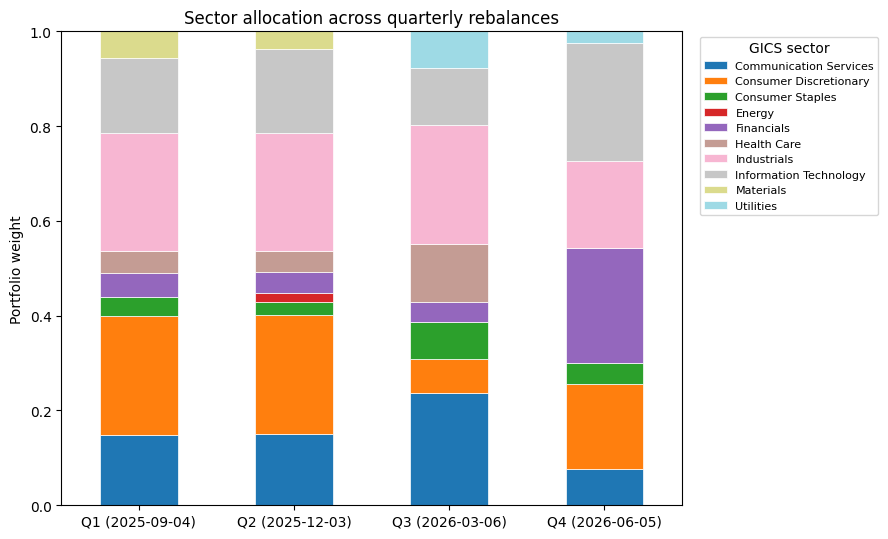


=== Change in sector weight vs previous quarter ===
                        Q2 (2025-12-03)  Q3 (2026-03-06)  Q4 (2026-06-05)
Communication Services         0.002000         0.085000        -0.159000
Consumer Discretionary         0.000000        -0.176000         0.105000
Consumer Staples              -0.014000         0.050000        -0.033000
Energy                         0.021000        -0.021000         0.000000
Financials                    -0.006000        -0.001000         0.200000
Health Care                   -0.003000         0.079000        -0.122000
Industrials                    0.000000        -0.000000        -0.067000
Information Technology         0.018000        -0.056000         0.129000
Materials                     -0.019000        -0.036000         0.000000
Utilities                      0.000000         0.077000        -0.053000


In [331]:
import matplotlib.pyplot as plt

def sector_weights(weights, sector_map):
    """Aggregate ticker-level weights into sector-level weights."""
    s = weights.groupby(weights.index.map(sector_map)).sum()
    return s

sector_history = pd.DataFrame({
    f"Q{row['quarter']} ({row['as_of_date']})": sector_weights(row["weights"], sector_map)
    for row in quarter_log
}).fillna(0.0).sort_index()

print("=== Sector allocation by quarter ===")
print(sector_history.round(3))

# Stacked bar chart
ax = sector_history.T.plot(
    kind="bar", stacked=True, figsize=(9, 5.5),
    colormap="tab20", edgecolor="white", linewidth=0.5
)
ax.set_ylabel("Portfolio weight")
ax.set_xlabel("")
ax.set_title("Sector allocation across quarterly rebalances")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, title="GICS sector")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

# Quarter-over-quarter change in each sector's weight
sector_change = sector_history.diff(axis=1).drop(columns=sector_history.columns[0])
print("\n=== Change in sector weight vs previous quarter ===")
print(sector_change.round(3))

### Supplementary — S&P 500 sector performance benchmark (equal-weighted, by quarter)
Gives the sector context referenced in the write-up ("none of the sectors delivered a consistently positive return... underscoring the need to hold a balanced portfolio") — included so a sector rotating in or out of the portfolio (seen in the chart above) can be read against how that sector actually performed that quarter, rather than in isolation.

In [332]:
def equal_weighted_sector_returns(period_start, period_end, price_panel, sector_map):
    """Equal-weighted simple return of every priced ticker over one quarter, grouped by GICS sector."""
    px = price_panel.loc[period_start:period_end]
    p0 = px.iloc[0]
    p1 = px.iloc[-1]
    simple_return = (p1 / p0 - 1)
    sector_of = pd.Series(simple_return.index.map(sector_map), index=simple_return.index)
    return simple_return.groupby(sector_of).mean()

sector_perf_cols = {}
for row in quarter_log:
    label = f"Q{row['quarter']} ({row['as_of_date']})"
    period_start = pd.Timestamp(row["as_of_date"])
    period_end = pd.Timestamp(row["period_end"])
    sector_perf_cols[label] = equal_weighted_sector_returns(period_start, period_end, price_panel, sector_map)

sector_perf_history = pd.DataFrame(sector_perf_cols).fillna(0.0).sort_index()
sector_perf_history["Cumulative"] = (1 + sector_perf_history).prod(axis=1) - 1

print("=== S&P 500 sector performance by quarter (equal-weighted) ===")
print(sector_perf_history.round(3))


=== S&P 500 sector performance by quarter (equal-weighted) ===
                        Q1 (2025-09-04)  Q2 (2025-12-03)  Q3 (2026-03-06)  Q4 (2026-06-05)  Cumulative
Ticker                                                                                                
Communication Services         0.001000         0.052000        -0.061000         0.021000    0.009000
Consumer Discretionary        -0.021000         0.000000        -0.030000         0.010000   -0.041000
Consumer Staples              -0.013000         0.098000        -0.035000         0.047000    0.096000
Energy                         0.060000         0.248000         0.041000         0.117000    0.539000
Financials                    -0.023000        -0.024000         0.039000         0.121000    0.111000
Health Care                    0.093000        -0.023000         0.006000         0.150000    0.236000
Industrials                    0.029000         0.086000         0.010000         0.008000    0.138000
Informatio

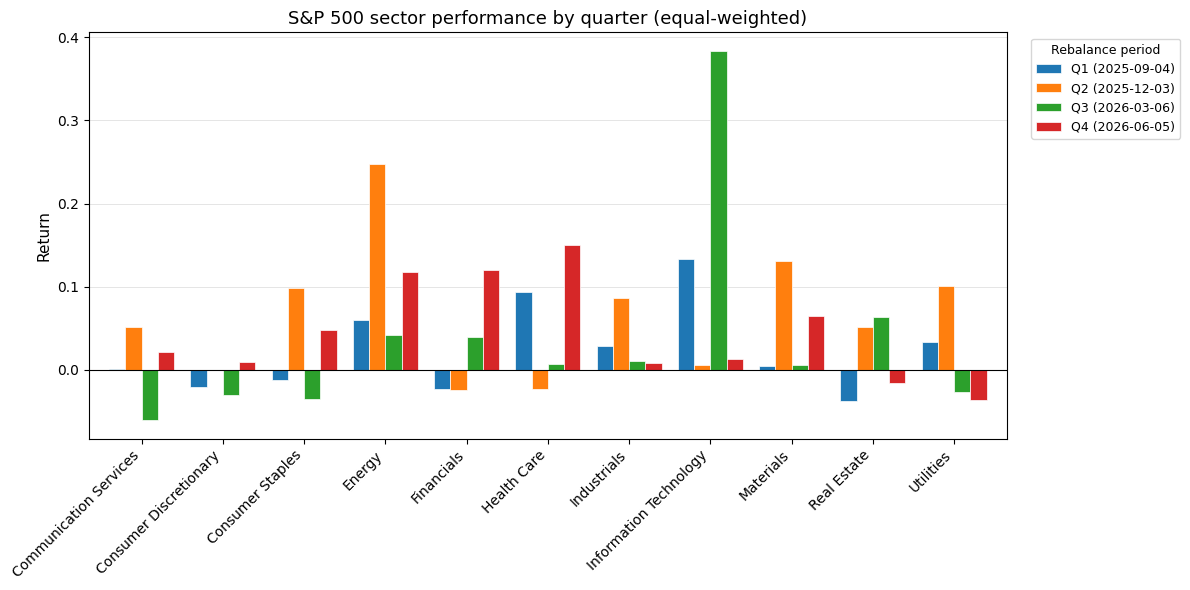

In [333]:
plot_df = sector_perf_history.drop(columns="Cumulative")

fig, ax = plt.subplots(figsize=(12, 6))
plot_df.plot(kind="bar", ax=ax, width=0.8, edgecolor="white", linewidth=0.5)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Return", fontsize=11)
ax.set_xlabel("")
ax.set_title("S&P 500 sector performance by quarter (equal-weighted)", fontsize=13)

# --- x-axis readability fixes ---
ax.set_xticklabels(plot_df.index, rotation=45, ha="right", fontsize=10)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="y", color="#e0e0e0", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)

ax.legend(title="Rebalance period", fontsize=9, title_fontsize=9,
          loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

## Quantifying and Validating Downside
(§ *Quantifying and Validating Downside*: historical-simulation VaR — chosen over parametric VaR because Jarque-Bera fails for daily equity returns, per § *Estimation of Expected Returns* — estimated from each quarter's own trailing estimation window, then backtested against what actually happened while that quarter's weights were held.)

**Why historical simulation, not parametric VaR:** the Estimation of Expected Returns section already found every stock fails the Jarque-Bera normality test — daily equity returns have fatter tails than a normal distribution assumes. A parametric VaR built on a normal-distribution assumption would understate real tail risk; historical simulation reads the loss threshold directly off the portfolio's own empirical return distribution instead, making no distributional assumption at all.

**Why estimate AND backtest, not just estimate:** a single VaR number is only useful if it's actually well-calibrated — estimating it once and never checking whether real losses breached it more often than the confidence level implies would be an untested claim. The Kupiec test below is exactly that check.

**Uses the same history length the portfolio itself was actually built on** for each quarter (`window_years` from `quarter_log`, set dynamically in Construction of Portfolio) rather than a fixed window — so if a given quarter's screened universe forced construction onto a 2- or 3-year window instead of the usual 1-year one, the VaR estimate is based on that same, consistent window.

In [334]:
CONFIDENCE = 0.95  # standard institutional choice; the proposal doesn't fix one, stated here explicitly

def historical_var(returns_series, confidence=0.95):
    """Positive number = the loss threshold implied by the confidence level, per your original notebook."""
    return -np.percentile(returns_series.dropna(), (1 - confidence) * 100)

def estimation_window_returns(weights, as_of_date, window_years):
    """Rebuilds the SAME trailing window construct_portfolio() actually used for this quarter
    (window_years comes from quarter_log, not a fixed guess), and returns the portfolio's
    historical daily (log) return series over that window -- the distribution the
    historical-simulation VaR is estimated from, consistent with your original Phase 7."""
    as_of_date = pd.Timestamp(as_of_date)
    window_start = as_of_date - pd.DateOffset(years=window_years)
    tickers = weights.index.tolist()
    prices_window = price_panel.loc[window_start:as_of_date, tickers]
    log_returns_window = np.log(prices_window / prices_window.shift(1)).dropna()
    return (log_returns_window * weights[tickers]).sum(axis=1)

def realised_daily_returns(weights, period_start, period_end):
    """Daily (log) returns actually realised while holding this quarter's fixed weights
    (buy-and-hold within the quarter, no intra-quarter rebalancing) — used to backtest the
    VaR estimate above against what actually happened."""
    tickers = weights.index.tolist()
    px = price_panel.loc[period_start:period_end, tickers]
    log_returns = np.log(px / px.shift(1)).dropna()
    return (log_returns * weights[tickers]).sum(axis=1)


In [335]:
# Estimate VaR as of each quarter's construction date, then check how many days during
# that quarter's HOLDING period breached it — aggregated for a Kupiec test below.
var_rows = []
all_breaches = 0
all_days = 0
realised_by_quarter = []   # kept (not discarded) to compute a realised Sharpe ratio / drawdown below

for row in quarter_log:
    weights = row["weights"]
    as_of_date = pd.Timestamp(row["as_of_date"])
    period_end = pd.Timestamp(row["period_end"])
    window_years = row["window_years"]   # <-- same window this quarter's portfolio was actually built on

    est_returns = estimation_window_returns(weights, as_of_date, window_years)
    var_q = historical_var(est_returns, CONFIDENCE)

    realised = realised_daily_returns(weights, as_of_date, period_end)
    breaches = int((realised < -var_q).sum())
    n_days = len(realised)

    var_rows.append({
        "quarter": row["quarter"],
        "as_of_date": row["as_of_date"],
        "period_end": row["period_end"],
        "window_years": window_years,
        "var_95_pct": var_q,
        "days_held": n_days,
        "breaches": breaches,
        "breach_rate": breaches / n_days,
    })

    all_breaches += breaches
    all_days += n_days
    realised_by_quarter.append(realised)

var_summary = pd.DataFrame(var_rows)
print("=== Historical simulation VaR — estimate at construction vs realised breaches ===")
print(var_summary)

print(f"\nAggregate across all {N_QUARTERS} quarters: {all_breaches} breaches over {all_days} trading days "
      f"({all_breaches/all_days:.2%} observed vs {1-CONFIDENCE:.0%} expected)")


=== Historical simulation VaR — estimate at construction vs realised breaches ===
   quarter  as_of_date  period_end  window_years  var_95_pct  days_held  breaches  breach_rate
0        1  2025-09-04  2025-12-03             3    0.018776         63         3     0.047619
1        2  2025-12-03  2026-03-06             3    0.024323         63         3     0.047619
2        3  2026-03-06  2026-06-05             3    0.013568         63         5     0.079365
3        4  2026-06-05  2026-09-04             3    0.020501         63         3     0.047619

Aggregate across all 4 quarters: 14 breaches over 252 trading days (5.56% observed vs 5% expected)


### Quantifying and Validating Downside — Kupiec coverage test
**Why a formal statistical test rather than just eyeballing the breach rate:** a 95% VaR should be breached on roughly 5% of days by construction — but with a small number of quarters, some deviation from exactly 5% is expected by chance alone. The Kupiec (1995) unconditional-coverage test asks whether the *observed* breach rate is statistically distinguishable from the *expected* one, rather than treating any deviation as evidence the model is miscalibrated.

In [336]:
from scipy.stats import chi2

def kupiec_test(n_breaches, n_total, confidence=0.95):
    p = 1 - confidence
    p_hat = n_breaches / n_total
    eps = 1e-10
    p_hat_safe = min(max(p_hat, eps), 1 - eps)

    log_lik_null = (n_total - n_breaches) * np.log(1 - p) + n_breaches * np.log(p)
    log_lik_alt = (n_total - n_breaches) * np.log(1 - p_hat_safe) + n_breaches * np.log(p_hat_safe)

    lr_stat = -2 * (log_lik_null - log_lik_alt)
    p_value = 1 - chi2.cdf(lr_stat, df=1)
    return lr_stat, p_value

lr_stat, p_value = kupiec_test(all_breaches, all_days, CONFIDENCE)
print(f"Kupiec LR statistic: {lr_stat:.4f}, p-value: {p_value:.4f}")
if p_value > 0.05:
    print("VaR model coverage looks reliable (fail to reject the null of correct coverage)")
else:
    print("VaR model coverage is statistically questionable (reject the null of correct coverage)")


Kupiec LR statistic: 0.1583, p-value: 0.6907
VaR model coverage looks reliable (fail to reject the null of correct coverage)


## Realised Risk-Adjusted Performance (Sharpe Ratio)
(§ *Validation of Approach*: your objective function is `w'\u03bc / (w'\u03a9w)^0.5` — return **per unit of risk**, not raw return in isolation. Section 3.5's cumulative-return comparison shows a modest shortfall against the index; that alone doesn't answer the question your actual mandate asks. This computes the realised Sharpe ratio and maximum drawdown directly, reusing the same daily portfolio returns already computed for the VaR backtest above, rather than relying on prose to argue what the risk-adjusted outcome was.)

In [337]:
# Reuses realised_by_quarter from the VaR backtest above -- these are the ACTUAL daily log
# returns the portfolio earned each quarter, already computed there to count VaR breaches.
# Concatenating them gives a genuine out-of-sample daily return series for the whole
# walk-forward period, rather than the 4-point quarterly series Section 3.5 uses (far too
# few observations to estimate volatility from reliably).
portfolio_returns_full = pd.concat(realised_by_quarter)

walkforward_start = pd.Timestamp(quarter_log[0]["as_of_date"])
walkforward_end = pd.Timestamp(quarter_log[-1]["period_end"])

spy_full_px = yf.download("SPY", start=walkforward_start,
                           end=(walkforward_end + pd.Timedelta(days=3)).strftime("%Y-%m-%d"),
                           auto_adjust=True, progress=False)["Close"]
if isinstance(spy_full_px, pd.DataFrame):
    spy_full_px = spy_full_px.squeeze("columns")
spy_returns_full = np.log(spy_full_px / spy_full_px.shift(1)).dropna()
spy_returns_full = spy_returns_full.loc[walkforward_start:walkforward_end]


def annualised_sharpe(daily_log_returns):
    return daily_log_returns.mean() / daily_log_returns.std() * np.sqrt(252)


def max_drawdown(daily_log_returns):
    cum_value = np.exp(daily_log_returns.cumsum())
    running_peak = cum_value.cummax()
    drawdown = cum_value / running_peak - 1
    return drawdown.min()


portfolio_sharpe = annualised_sharpe(portfolio_returns_full)
spy_sharpe = annualised_sharpe(spy_returns_full)
portfolio_mdd = max_drawdown(portfolio_returns_full)
spy_mdd = max_drawdown(spy_returns_full)

# --- Equal-weighted comparison for the REAL, live walk-forward portfolio ---
# The equal-weighted comparison in Section 5.1.3 only ever tested a small, static,
# 9-company calibration universe held for 2 years with no rebalancing -- it has never
# been tested against the actual live strategy (re-screened, quarterly-rebalanced,
# 17-27 stocks). This computes that comparison directly, reusing realised_daily_returns
# (already defined above for the VaR backtest) with equal weights instead of the
# optimised ones, over the exact same quarters and screened universe each time.
equal_weighted_by_quarter = []
for row in quarter_log:
    tickers_this_quarter = row["weights"].index.tolist()   # the screened universe that quarter
    equal_weights = pd.Series(1 / len(tickers_this_quarter), index=tickers_this_quarter)
    as_of_date = pd.Timestamp(row["as_of_date"])
    period_end = pd.Timestamp(row["period_end"])
    equal_weighted_by_quarter.append(realised_daily_returns(equal_weights, as_of_date, period_end))

equal_weighted_returns_full = pd.concat(equal_weighted_by_quarter)
eq_live_sharpe = annualised_sharpe(equal_weighted_returns_full)
eq_live_mdd = max_drawdown(equal_weighted_returns_full)
eq_live_vol = equal_weighted_returns_full.std() * np.sqrt(252)

print(f"Realised performance, {walkforward_start.date()} to {walkforward_end.date()} "
      f"({len(portfolio_returns_full)} trading days):\n")
print(f"{'':20}{'Portfolio':>15}{'Equal-Weighted':>18}{'S&P 500':>15}")
print(f"{'Annualised Sharpe':20}{portfolio_sharpe:>15.3f}{eq_live_sharpe:>18.3f}{spy_sharpe:>15.3f}")
print(f"{'Maximum drawdown':20}{portfolio_mdd:>15.2%}{eq_live_mdd:>18.2%}{spy_mdd:>15.2%}")
print(f"{'Annualised volatility':20}{portfolio_returns_full.std() * np.sqrt(252):>15.2%}"
      f"{eq_live_vol:>18.2%}{spy_returns_full.std() * np.sqrt(252):>15.2%}")


Realised performance, 2025-09-04 to 2026-09-04 (252 trading days):

                          Portfolio    Equal-Weighted        S&P 500
Annualised Sharpe             0.386             0.082          1.423
Maximum drawdown            -15.07%           -12.50%         -8.88%
Annualised volatility         19.85%            16.06%         12.79%


## Summary — what to actually report

| Question | Where the answer comes from | Notes |
|---|---|---|
| Which factor model? (Carhart vs CAPM vs FF3F) | Part A — Model Comparison | Shares the comparison period with Window/Frequency below |
| Which lambda penalty? | Part A — Lambda Sensitivity | Same |
| Which window length / rebalance frequency? | Part A — Window/Frequency Comparison | Rolling, re-screened, same comparison period |
| What's the strategy's real Sharpe/return/alpha vs SPY? | **Part B** | Separate, later, non-overlapping period |
| What's the portfolio's actual downside risk (VaR)? | **Part B** | Estimated & backtested per quarter |

**Still open / deliberately out of scope, flagged rather than silently skipped:**
- Model Comparison/Lambda Sensitivity and Window/Frequency Comparison share one `COMPARISON_START`-to-`REBALANCE_START` period rather than each getting a fully independent one — a deliberate trade-off after three disjoint periods proved impossible to fit around COVID without breaking screening (see Experiment Configuration).
- Stage 1 screening's `sharpe > 0` filter (§ *Screening*) — a judgement call, not something the proposal specifies.
- A **nested walk-forward** (re-running the whole Part A comparison fresh inside every period of Part B, so the adopted policy itself can evolve over time) would be the next level of rigour beyond this — a substantially larger feature than what's built here.

## Export — results for the live dashboard

Writes `docs/data/latest.json` (read by `docs/index.html`). Runs at the end of every scheduled re-execution, so the dashboard always shows the latest walk-forward quarter and the current target allocation.

In [ ]:
# --- Export results for the dashboard: docs/data/latest.json ---
import json, pathlib, datetime as _dt

def _records(df):
    out = []
    for r in df.to_dict("records"):
        out.append({k: (str(v) if isinstance(v, (pd.Timestamp, _dt.date)) else
                        (None if isinstance(v, float) and np.isnan(v) else (float(v) if isinstance(v, (np.floating, float)) else
                        (int(v) if isinstance(v, (np.integer,)) else v)))) for k, v in r.items()})
    return out

_rec = []
for _t, _w in client_weights.sort_values(ascending=False).items():
    _mu = client_carhart_df.loc[_t, "expected_log_return_daily"] * ADOPTED_REBALANCE_DAYS
    _rec.append({"ticker": _t, "sector": sector_map.get(_t, "Unknown"), "weight": float(_w),
                 "expected_return_next_rebalance": float(np.exp(_mu) - 1)})

_export = {
    "generated_utc": _dt.datetime.now(_dt.timezone.utc).isoformat(timespec="seconds"),
    "data_through": str(price_panel.index.max().date()),
    "policy": {"window_years": int(ADOPTED_WINDOW_YEARS), "rebalance_days": int(ADOPTED_REBALANCE_DAYS),
               "initial_capital": float(INITIAL_CAPITAL), "walk_forward_start": str(REBALANCE_START.date()),
               "n_full_periods": int(N_QUARTERS)},
    "quarters": _records(quarterly_summary_extended),
    "cumulative": _records(cumulative_extended),
    "totals": {"portfolio_return": float(total_portfolio_return_extended), "spy_return": float(total_spy_return_extended),
               "full_periods_portfolio_return": float(total_portfolio_return), "full_periods_spy_return": float(total_spy_return)},
    "var": {"confidence": float(CONFIDENCE), "by_quarter": _records(var_summary), "breaches": int(all_breaches),
            "days": int(all_days), "kupiec_lr": float(lr_stat), "kupiec_p": float(p_value)},
    "recommendation": {"as_of": str(last_construction["as_of_date"]), "window_years": int(client_window_years),
                       "holdings": _rec},
}
_out = pathlib.Path("docs/data")
_out.mkdir(parents=True, exist_ok=True)
(_out / "latest.json").write_text(json.dumps(_export, indent=1))
print("Exported", _out / "latest.json", "| data through", _export["data_through"])
